# Porto Taxi — EDA để tự chọn vùng nghiên cứu

Notebook này khảo sát metadata toàn file và GPS của **mẫu có ưu tiên giờ cao điểm**.
Mục tiêu là cung cấp bằng chứng về độ phủ chuyến/taxi/ngày/giờ để bạn tự chọn vùng.
Không tải road graph, không đếm cạnh, không map matching, không xây mô hình hoặc demo.
Ô lưới không phải cạnh đường. Mục tiêu 5.000–7.000 cạnh cần kiểm tra ở giai đoạn sau,
không thể suy ra từ số chuyến, số GPS hay số ô ở đây.


Ba nhóm giờ khởi tạo: sáng 07:00–09:00, chiều 16:00–19:00, còn lại ngoài cao điểm.
Đây là **giả định lấy mẫu**, không phải kết quả xác nhận giờ cao điểm thực tế của Porto.

> **Bố cục repo:** notebook đã được chuyển vào thư mục theo bước và tự tìm thư mục gốc. Các output đang hiển thị được giữ từ lượt thực thi trước khi sắp xếp đường dẫn; không chạy lại matching/train trong bước sắp xếp này. Run All tiếp theo sẽ dùng đường dẫn mới và cache hợp lệ.

## A. Cấu hình — sửa đường dẫn, khoảng ngày và số chuyến tại đây

Tỷ lệ 70% cao điểm được chia đều cho sáng/chiều theo mặc định; quota được phân bổ
khá đều giữa các ngày, có điều chỉnh khi tầng không đủ chuyến. Khoảng ngày là nửa mở.
Bounding box kiểm tra GPS dưới đây rất rộng, không phải vùng nghiên cứu được chọn.

In [1]:
from pathlib import Path
import ast, json

# Locate the repository from either its root or a notebook subfolder.
_current_dir = Path.cwd().resolve()
ROOT = next((candidate for candidate in (_current_dir, *_current_dir.parents)
             if (candidate / "notebooks").is_dir() and (candidate / "requirements").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the cloned repository (notebooks/ and requirements/ must exist).")
OLD_PATH = ROOT / "notebooks/00_full_pipeline/porto_trajectory_mining.ipynb"
OLD_CONFIG = {}
if OLD_PATH.exists():
    for cell in json.loads(OLD_PATH.read_text(encoding="utf-8"))["cells"]:
        if cell["cell_type"] != "code":
            continue
        source = "".join(cell["source"]) if isinstance(cell["source"],list) else cell["source"]
        for node in ast.parse(source).body:
            if isinstance(node,ast.Assign) and any(isinstance(t,ast.Name) and t.id=="CFG" for t in node.targets) and isinstance(node.value,ast.Dict):
                for key,value in zip(node.value.keys,node.value.values):
                    try:
                        OLD_CONFIG[ast.literal_eval(key)] = ast.literal_eval(value)
                    except (ValueError,TypeError):
                        continue

CFG = {
    "data_path": OLD_CONFIG.get("data_path","data/train.csv"),
    "zip_member": None,
    "cache_dir": "cache/region_eda", "output_dir": "outputs/region_eda",
    "seed": OLD_CONFIG.get("seed",313), "timezone": "Europe/Lisbon",
    "study_start": OLD_CONFIG.get("study_start","2013-07-01T00:00:00+01:00"),
    "study_end": OLD_CONFIG.get("train_end","2013-08-05T00:00:00+01:00"),
    "chunk_size": 25000, "sample_trips": 10000,
    "peak_windows": {"morning_peak": [7,9], "evening_peak": [16,19]},
    "peak_fraction": .70, "morning_share_of_peak": .50,
    "gps_interval_s": 15, "min_trip_points": 4, "min_segment_points": 2,
    "max_gps_speed_kmh": 150,
    "broad_geo_bbox": [-10.0,38.0,-6.0,43.0],  # chỉ phát hiện outlier địa lý rất rộng
    "metric_crs": "EPSG:32629", "grid_size_m": 500,
    "time_bin_minutes": 60, "day_grouping": "weekday_weekend",
    "regions": [],                         # hoặc nhập ở cell R1 gần cuối notebook
    "heatmap_cell_ids": [],                # nhập cell_id hoặc dùng các ô ví dụ có ghi rõ
    "max_map_cells": 6000, "trajectory_examples": 12,
    "map_center": [41.1579,-8.6291], "map_zoom": 12,
    "static_view_radius_m": 12000,           # chỉ khung nhìn PNG, không lọc dữ liệu
    "map_tiles": "OpenStreetMap",           # None nếu không cần nền tiles
    "max_region_grid_cells": 50000,
    "coverage_min_trips": 20, "coverage_min_taxis": 5, "coverage_min_days": 10,
    "force_metadata": False, "force_sample": False, "force_clean": False,
    "force_grid": False, "force_regions": False, "verify_full_hash": False,
    "run_logic_tests": True,
}

## B. Môi trường và nhật ký

Cài package còn thiếu bằng cell hướng dẫn rồi restart kernel. Folium là tùy chọn:
thiếu Folium vẫn có bảng và PNG. HTML mở trực tiếp không cần Python/server; thư viện
JavaScript/CSS CDN và tiles nền cần mạng khi trình duyệt chưa cache. PNG luôn dùng được
offline. Không có truy vấn Overpass/OSMnx hoặc tải mạng đường trong notebook này.

In [2]:
# %pip install "numpy>=1.26" "pandas>=2.2" "pyarrow>=15" "shapely>=2.1" "pyproj>=3.6" "geopandas>=1" "matplotlib>=3.9" psutil folium branca nbformat nbclient ipykernel tzdata

In [3]:
import os, sys, time, hashlib, sqlite3, zipfile, contextlib, importlib.util, importlib.metadata
from collections import Counter
from datetime import datetime, timezone
import math, re, html

REQUIRED = {"numpy":"numpy","pandas":"pandas","pyarrow":"pyarrow","shapely":"shapely",
            "pyproj":"pyproj","geopandas":"geopandas","matplotlib":"matplotlib","psutil":"psutil"}
missing = [dist for mod,dist in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    raise RuntimeError("Thiếu package: "+", ".join(missing)+"; cài ở cell B rồi restart kernel.")
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Point, LineString, box, mapping
from pyproj import Transformer, Geod
import matplotlib.pyplot as plt
import psutil
from IPython.display import display, Markdown

HAS_FOLIUM = importlib.util.find_spec("folium") is not None
if HAS_FOLIUM:
    import folium
    import branca.colormap as bcm

def digest(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=False,default=str).encode()).hexdigest()

def write_json(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+".tmp")
    temp.write_text(json.dumps(value,ensure_ascii=False,indent=2,default=str),encoding="utf-8")
    temp.replace(path)

def save_table(frame,path,scope=None,csv=True):
    frame=frame.copy()
    if scope is not None:
        frame["scope"]=scope
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(".tmp.parquet")
    frame.to_parquet(temporary,index=False); temporary.replace(path)
    if csv:
        frame.to_csv(path.with_suffix(".csv"),index=False,encoding="utf-8-sig")

def as_utc(value):
    t=pd.Timestamp(value)
    if t.tzinfo is None:
        raise ValueError("Ngày cấu hình phải có timezone/UTC offset.")
    return t.tz_convert("UTC")

START,END=as_utc(CFG["study_start"]),as_utc(CFG["study_end"])
assert START<END and CFG["sample_trips"]>0 and 0<=CFG["peak_fraction"]<=1
assert 0<=CFG["morning_share_of_peak"]<=1
assert CFG["grid_size_m"]>0 and 1440%CFG["time_bin_minutes"]==0
assert CFG["day_grouping"] in ["weekday","weekday_weekend"]
for a,b in CFG["peak_windows"].values():
    assert 0<=a<b<=24
am,pm=CFG["peak_windows"]["morning_peak"],CFG["peak_windows"]["evening_peak"]
assert am[1]<=pm[0] or pm[1]<=am[0]

CACHE=ROOT/CFG["cache_dir"]; OUTPUT=ROOT/CFG["output_dir"]
for folder in [CACHE,OUTPUT]: folder.mkdir(parents=True,exist_ok=True)
VERSIONS={dist:importlib.metadata.version(dist) for dist in REQUIRED.values()}
VERSIONS["folium"]=importlib.metadata.version("folium") if HAS_FOLIUM else "not installed"
PROJECT=Transformer.from_crs("EPSG:4326",CFG["metric_crs"],always_xy=True)
UNPROJECT=Transformer.from_crs(CFG["metric_crs"],"EPSG:4326",always_xy=True)
GEOD=Geod(ellps="WGS84")

def stage_hash(stage):
    path=ROOT/"notebooks/01_region_eda/porto_region_eda.ipynb"
    if not path.exists(): return digest(["region-eda-v1",stage])
    cells=json.loads(path.read_text(encoding="utf-8"))["cells"]
    return digest([c["source"] for c in cells if c.get("metadata",{}).get("eda_stage") in ["common",stage]])

RUN=OUTPUT/(datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
RUN.mkdir(exist_ok=True); FIGURES=RUN/"figures"; MAPS=RUN/"maps"
FIGURES.mkdir(exist_ok=True); MAPS.mkdir(exist_ok=True)
RUNTIME=[]; STATUS={}
SCOPE_META_ALL="Toàn file: TRIP_ID duy nhất, metadata hợp lệ; chưa kiểm tra GPS"
SCOPE_META_STUDY="Khoảng nghiên cứu: TRIP_ID duy nhất, metadata hợp lệ; chưa kiểm tra GPS"
SCOPE_SAMPLE="Mẫu ưu tiên cao điểm, sau làm sạch GPS; không đại diện tỷ lệ nhu cầu toàn thành phố"

def status(stage,state,message):
    STATUS[stage]={"status":state,"message":str(message)}
    write_json(RUN/"status.json",STATUS)
    print(f"[{stage}] {state}: {message}")

@contextlib.contextmanager
def timed(name):
    start=time.perf_counter(); process=psutil.Process(); before=process.memory_info().rss/2**20
    try:
        yield
    finally:
        row={"stage":name,"seconds":time.perf_counter()-start,"rss_before_mb":before,
             "rss_after_mb":process.memory_info().rss/2**20}
        RUNTIME.append(row); write_json(RUN/"runtime.json",RUNTIME)
        print(f"{name}: {row['seconds']:.1f}s; RSS cuối bước={row['rss_after_mb']:.1f} MiB (không phải peak)")

def figure(name,scope):
    plt.gcf().suptitle(scope,fontsize=9)
    plt.tight_layout(rect=(0,0,1,.95)); plt.savefig(FIGURES/(name+".png"),dpi=140,bbox_inches="tight")
    plt.show(); plt.close()

def period_for_minutes(minutes):
    values=np.asarray(minutes)
    labels=np.full(values.shape,"off_peak",dtype=object)
    for name,(begin,end) in CFG["peak_windows"].items():
        labels[(values>=begin*60)&(values<end*60)]=name
    return labels

def point_time_columns(frame):
    f=frame.copy(); local=pd.to_datetime(f.timestamp,unit="s",utc=True).dt.tz_convert(CFG["timezone"])
    minutes=local.dt.hour*60+local.dt.minute
    f["date"]=local.dt.strftime("%Y-%m-%d"); f["weekday"]=local.dt.weekday.astype("int8")
    f["hour"]=local.dt.hour.astype("int8"); f["slot"]=(minutes//CFG["time_bin_minutes"]).astype("int16")
    f["period"]=period_for_minutes(minutes)
    f["day_group"]=f.weekday.astype(str) if CFG["day_grouping"]=="weekday" else np.where(f.weekday<5,"weekday","weekend")
    return f

write_json(RUN/"config.json",CFG)
write_json(RUN/"environment.json",{"python":sys.version,"packages":VERSIONS,"old_config_reference":str(OLD_PATH),
           "old_train_end":OLD_CONFIG.get("train_end"),"timezone":CFG["timezone"]})
display(pd.Series(VERSIONS,name="version").to_frame())
print("Khoảng khảo sát:",START.tz_convert(CFG["timezone"]),"→",END.tz_convert(CFG["timezone"]))
print("Output:",RUN)

,version
numpy,2.1.3
pandas,2.3.2
pyarrow,23.0.1
shapely,2.2.0
pyproj,3.8.0
geopandas,1.2.0
matplotlib,3.10.0
psutil,7.1.0
folium,0.20.0


Khoảng khảo sát: 2013-07-01 00:00:00+01:00 → 2013-08-05 00:00:00+01:00
Output: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_eda\20261021T155220459810Z


### B1. Bố trí kết quả CSV

Tất cả CSV được gom vào `outputs/csv/`, giữ đường dẫn con theo notebook/lần chạy.
Ví dụ bảng lưới ở `outputs/csv/region_eda/<run_id>/grid_cells.csv`; bảng vùng ở
`outputs/csv/region_eda/<run_id>/regions/<region_key>/comparison.csv`.
Parquet, HTML, PNG và metadata vẫn ở vị trí cũ. Cell này chỉ thay nơi xuất CSV,
không đổi xử lý dữ liệu hoặc khóa cache của metadata/mẫu/GPS/lưới.

In [ ]:
CSV_ROOT=OUTPUT.parent/"csv"

def csv_output_path(path):
    path=Path(path).resolve()
    try:
        relative=path.relative_to(OUTPUT.parent.resolve())
    except ValueError:
        return path.with_suffix(".csv")
    if relative.parts and relative.parts[0]=="csv":
        return path.with_suffix(".csv")
    return CSV_ROOT/relative.with_suffix(".csv")

def save_table(frame,path,scope=None,csv=True):
    frame=frame.copy()
    if scope is not None:
        frame["scope"]=scope
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(".tmp.parquet")
    frame.to_parquet(temporary,index=False); temporary.replace(path)
    if csv:
        csv_path=csv_output_path(path)
        csv_path.parent.mkdir(parents=True,exist_ok=True)
        frame.to_csv(csv_path,index=False,encoding="utf-8-sig")

## C. Metadata toàn file và trong khoảng nghiên cứu

SQLite lưu metadata trên đĩa để đếm distinct và chọn mẫu qua nhiều lần chạy.
Lượt đọc đầu chỉ đọc các cột metadata, không parse POLYLINE. Hỗ trợ alias DAY_TYPE
thành DAYTYPE; cột đó chỉ được kiểm tra missing, không dùng phân nhóm ngày.
“Hợp lệ metadata” cần ID chuyến/taxi, timestamp Unix nguyên hợp lệ, MISSING_DATA=False.
Chất lượng GPS chỉ được kiểm tra ở mẫu sau này. TRIP_ID trùng giữ lần xuất hiện đầu tiên.
Các trường ORIGIN_CALL/STAND có thể thiếu hợp lệ theo loại gọi xe; không coi mọi NA là lỗi.

Chart giờ ở mục này là **giờ bắt đầu chuyến**, không phải số xe đồng thời hay ùn tắc.

In [4]:
@contextlib.contextmanager
def input_stream(path,member=None):
    path=Path(path)
    if path.suffix.lower()==".zip":
        with zipfile.ZipFile(path) as archive:
            candidates=[name for name in archive.namelist() if Path(name).name.lower()=="train.csv"]
            if member is None:
                if len(candidates)!=1: raise ValueError("ZIP phải có đúng một train.csv hoặc đặt zip_member.")
                member=candidates[0]
            if Path(member).name.lower()!="train.csv": raise ValueError("Không dùng test.csv của cuộc thi.")
            with archive.open(member) as stream: yield stream
    else:
        if path.name.lower()=="test.csv": raise ValueError("Cần train.csv đầy đủ.")
        with path.open("rb") as stream: yield stream

def input_fingerprint(path):
    path=Path(path); stat=path.stat()
    identity={"path":str(path.resolve()),"size":stat.st_size,"mtime_ns":stat.st_mtime_ns}
    memo=CACHE/"file_hash_memo.json"
    saved=json.loads(memo.read_text(encoding="utf-8")) if memo.exists() else {}
    if saved.get("identity")==identity and not CFG["verify_full_hash"]:
        return saved
    sha=hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b""): sha.update(block)
    result={"identity":identity,"sha256":sha.hexdigest()}; write_json(memo,result)
    return result

def schema_for(path):
    with input_stream(path,CFG["zip_member"]) as stream:
        columns=pd.read_csv(stream,nrows=0).columns.tolist()
    aliases={"DAY_TYPE":"DAYTYPE"} if "DAYTYPE" not in columns else {}
    normalized=[aliases.get(c,c) for c in columns]
    expected=["TRIP_ID","CALL_TYPE","ORIGIN_CALL","ORIGIN_STAND","TAXI_ID","TIMESTAMP","DAYTYPE","MISSING_DATA","POLYLINE"]
    absent=set(expected)-set(normalized)
    if absent: raise ValueError("Thiếu schema: "+", ".join(sorted(absent)))
    return columns,aliases

def metadata_database(path,fingerprint):
    key=digest([fingerprint["sha256"],CFG["zip_member"],CFG["timezone"],CFG["peak_windows"],stage_hash("metadata")])[:20]
    folder=CACHE/"metadata"/key; folder.mkdir(parents=True,exist_ok=True)
    db=folder/"trips.sqlite"; marker=folder/"complete.json"
    if marker.exists() and db.exists() and not CFG["force_metadata"]:
        return db,json.loads(marker.read_text(encoding="utf-8")),key
    marker.unlink(missing_ok=True)
    columns,aliases=schema_for(path)
    selected_columns=[c for c in columns if c!="POLYLINE"]
    report=Counter(); missing_counts=Counter(); offset=0
    with contextlib.closing(sqlite3.connect(db)) as connection:
        connection.execute("DROP TABLE IF EXISTS trips")
        connection.execute("CREATE TABLE trips(trip_id TEXT PRIMARY KEY,taxi_id TEXT,timestamp INTEGER,day TEXT,month TEXT,weekday INTEGER,hour INTEGER,period TEXT,call_type TEXT,missing_flag TEXT,status TEXT,source_row INTEGER)")
        with input_stream(path,CFG["zip_member"]) as stream:
            for chunk in pd.read_csv(stream,usecols=selected_columns,dtype="string",chunksize=CFG["chunk_size"]):
                chunk=chunk.rename(columns=aliases)
                for c in chunk:
                    chunk[c]=chunk[c].str.strip().replace("",pd.NA)
                    missing_counts[c]+=int(chunk[c].isna().sum())
                numeric=pd.to_numeric(chunk.TIMESTAMP,errors="coerce")
                integer=numeric.notna() & (numeric%1).eq(0)
                times=pd.to_datetime(numeric.where(integer),unit="s",utc=True,errors="coerce")
                local=times.dt.tz_convert(CFG["timezone"])
                flag=chunk.MISSING_DATA.str.lower().map({"true":"true","1":"true","false":"false","0":"false"}).fillna("invalid")
                reasons=np.select([chunk.TAXI_ID.isna(),times.isna(),flag.eq("invalid"),flag.eq("true")],
                                  ["taxi_id_missing","timestamp_invalid","missing_flag_invalid","missing_data_true"],default="metadata_valid")
                minutes=local.dt.hour*60+local.dt.minute
                frame=pd.DataFrame({"trip_id":chunk.TRIP_ID,"taxi_id":chunk.TAXI_ID,
                    "timestamp":numeric.where(times.notna()),"day":local.dt.strftime("%Y-%m-%d"),"month":local.dt.strftime("%Y-%m"),
                    "weekday":local.dt.weekday,"hour":local.dt.hour,"period":period_for_minutes(minutes),
                    "call_type":chunk.CALL_TYPE,"missing_flag":flag,"status":reasons,
                    "source_row":np.arange(offset,offset+len(chunk))})
                report["raw_rows"]+=len(chunk); report["missing_trip_id_rows"]+=int(chunk.TRIP_ID.isna().sum())
                report["invalid_timestamp_rows"]+=int(times.isna().sum())
                report["missing_data_true_rows"]+=int(flag.eq("true").sum())
                report["invalid_missing_flag_rows"]+=int(flag.eq("invalid").sum())
                report["invalid_call_type_rows"]+=int((chunk.CALL_TYPE.notna() & ~chunk.CALL_TYPE.isin(["A","B","C"])).sum())
                for c in ["ORIGIN_CALL","ORIGIN_STAND"]:
                    values=pd.to_numeric(chunk[c],errors="coerce")
                    report["invalid_"+c.lower()+"_rows"]+=int((chunk[c].notna() & (values.isna() | values.lt(0) | (values%1).ne(0))).sum())
                frame=frame[frame.trip_id.notna()].astype(object).where(pd.notna(frame),None)
                before=connection.total_changes
                connection.executemany("INSERT OR IGNORE INTO trips VALUES (?,?,?,?,?,?,?,?,?,?,?,?)",frame.itertuples(index=False,name=None))
                report["duplicate_trip_id_rows"]+=len(frame)-(connection.total_changes-before)
                connection.commit(); offset+=len(chunk)
                if offset%(CFG["chunk_size"]*10)==0: print(f"Metadata: đã quét {offset:,} dòng")
        connection.execute("CREATE INDEX IF NOT EXISTS status_time ON trips(status,timestamp)")
        connection.execute("CREATE INDEX IF NOT EXISTS day_period ON trips(day,period,status)")
        connection.commit()
        report["unique_nonmissing_trip_ids"]=connection.execute("SELECT COUNT(*) FROM trips").fetchone()[0]
    result={"counts":dict(report),"missing_by_column":dict(missing_counts),"columns":columns,"aliases":aliases,
            "data_sha256":fingerprint["sha256"],"metadata_key":key,
            "not_inspected":"Missing/invalid POLYLINE toàn file chưa kiểm tra; chỉ parse GPS mẫu.",
            "complete_utc":datetime.now(timezone.utc).isoformat()}
    write_json(marker,result)
    return db,result,key

def metadata_eda(db,report):
    tables={}; summary=[]
    with contextlib.closing(sqlite3.connect(db)) as con:
        for name,condition,parameters,scope in [
            ("all","status='metadata_valid'",[],SCOPE_META_ALL),
            ("study","status='metadata_valid' AND timestamp>=? AND timestamp<?",[int(START.timestamp()),int(END.timestamp())],SCOPE_META_STUDY)]:
            values=con.execute(f"SELECT COUNT(*),COUNT(DISTINCT taxi_id),COUNT(DISTINCT day),MIN(timestamp),MAX(timestamp) FROM trips WHERE {condition}",parameters).fetchone()
            summary.append({"scope":scope,"trips":values[0],"taxis":values[1],"days":values[2],
                            "min_start_utc":str(pd.to_datetime(values[3],unit="s",utc=True)),"max_start_utc":str(pd.to_datetime(values[4],unit="s",utc=True))})
            for label,keys in [("month",["month"]),("day",["day"]),("weekday",["weekday"]),("hour",["hour"]),
                               ("weekday_hour",["weekday","hour"]),("taxi",["taxi_id"]),("call_type",["call_type"]),
                               ("strata",["day","period"]),("period",["period"])]:
                columns=",".join(keys)
                table=pd.read_sql_query(f"SELECT {columns},COUNT(*) trips FROM trips WHERE {condition} GROUP BY {columns} ORDER BY {columns}",con,params=parameters)
                tables[name+"_"+label]=table
                save_table(table,RUN/f"metadata_{name}_{label}.parquet",scope)
            status_table=pd.read_sql_query("SELECT status,COUNT(*) trips FROM trips GROUP BY status",con)
        flags=pd.read_sql_query("SELECT missing_flag,COUNT(*) trips FROM trips GROUP BY missing_flag",con)
    full_counts=pd.DataFrame([{"item":k,"count":v} for k,v in report["counts"].items()])
    full_counts["scope"]="Toàn file: số dòng thô; duplicate đếm trên TRIP_ID không thiếu"
    missing=pd.DataFrame([{"column":k,"missing_rows":v,"missing_fraction":v/max(1,report['counts']['raw_rows'])} for k,v in report["missing_by_column"].items()])
    flags["fraction"]=flags.trips/flags.trips.sum()
    save_table(full_counts,RUN/"metadata_raw_counts.parquet")
    save_table(missing,RUN/"metadata_raw_missing.parquet","Toàn file: metadata thô, chưa kiểm tra POLYLINE")
    save_table(status_table,RUN/"metadata_unique_status.parquet","Toàn file: TRIP_ID duy nhất")
    save_table(flags,RUN/"metadata_missing_flag.parquet","Toàn file: TRIP_ID duy nhất")
    save_table(pd.DataFrame(summary),RUN/"metadata_scopes.parquet")
    write_json(RUN/"metadata_report.json",report)
    display(full_counts); display(pd.DataFrame(summary)); display(missing); display(flags)
    for name,scope in [("all",SCOPE_META_ALL),("study",SCOPE_META_STUDY)]:
        fig,axes=plt.subplots(2,2,figsize=(13,8))
        daily=tables[name+"_day"]
        axes[0,0].plot(pd.to_datetime(daily.day),daily.trips); axes[0,0].set(title="Chuyến theo ngày bắt đầu",ylabel="Chuyến")
        hourly=tables[name+"_hour"].set_index("hour").trips.reindex(range(24),fill_value=0)
        axes[0,1].bar(hourly.index,hourly.values); axes[0,1].set(title="Giờ bắt đầu chuyến — Lisbon",xlabel="Giờ",ylabel="Chuyến")
        heat=tables[name+"_weekday_hour"].pivot(index="weekday",columns="hour",values="trips").reindex(index=range(7),columns=range(24)).fillna(0)
        image=axes[1,0].imshow(heat,aspect="auto",cmap="viridis"); fig.colorbar(image,ax=axes[1,0])
        axes[1,0].set(title="Thứ × giờ BẮT ĐẦU chuyến",xlabel="Giờ",ylabel="Thứ (0=Hai, 6=CN)")
        axes[1,1].hist(tables[name+"_taxi"].trips,bins=35); axes[1,1].set(title="Phân bố số chuyến / TAXI_ID",xlabel="Chuyến / taxi",ylabel="Taxi")
        figure("metadata_"+name,scope+"; giờ bắt đầu, không phải xe đồng thời/ùn tắc")
        display(tables[name+"_call_type"].assign(scope=scope))
    return tables

,item,count,scope
0,raw_rows,1710670,Toàn file: số dòng thô; duplicate đếm trên TRI...
1,missing_trip_id_rows,0,Toàn file: số dòng thô; duplicate đếm trên TRI...
2,invalid_timestamp_rows,0,Toàn file: số dòng thô; duplicate đếm trên TRI...
3,missing_data_true_rows,10,Toàn file: số dòng thô; duplicate đếm trên TRI...
4,invalid_missing_flag_rows,0,Toàn file: số dòng thô; duplicate đếm trên TRI...
5,invalid_call_type_rows,0,Toàn file: số dòng thô; duplicate đếm trên TRI...
6,invalid_origin_call_rows,0,Toàn file: số dòng thô; duplicate đếm trên TRI...
7,invalid_origin_stand_rows,0,Toàn file: số dòng thô; duplicate đếm trên TRI...
8,duplicate_trip_id_rows,81,Toàn file: số dòng thô; duplicate đếm trên TRI...
9,unique_nonmissing_trip_ids,1710589,Toàn file: số dòng thô; duplicate đếm trên TRI...


,scope,trips,taxis,days,min_start_utc,max_start_utc
0,"Toàn file: TRIP_ID duy nhất, metadata hợp lệ; ...",1710579,448,366,2013-07-01 00:00:53+00:00,2014-06-30 23:59:56+00:00
1,"Khoảng nghiên cứu: TRIP_ID duy nhất, metadata ...",162803,434,35,2013-07-01 00:00:53+00:00,2013-08-04 22:59:47+00:00


,column,missing_rows,missing_fraction
0,TRIP_ID,0,0.000000
1,CALL_TYPE,0,0.000000
2,ORIGIN_CALL,1345900,0.786768
3,ORIGIN_STAND,904091,0.528501
4,TAXI_ID,0,0.000000
5,TIMESTAMP,0,0.000000
6,DAYTYPE,0,0.000000
7,MISSING_DATA,0,0.000000


,missing_flag,trips,fraction
0,false,1710579,0.999994
1,true,10,0.000006


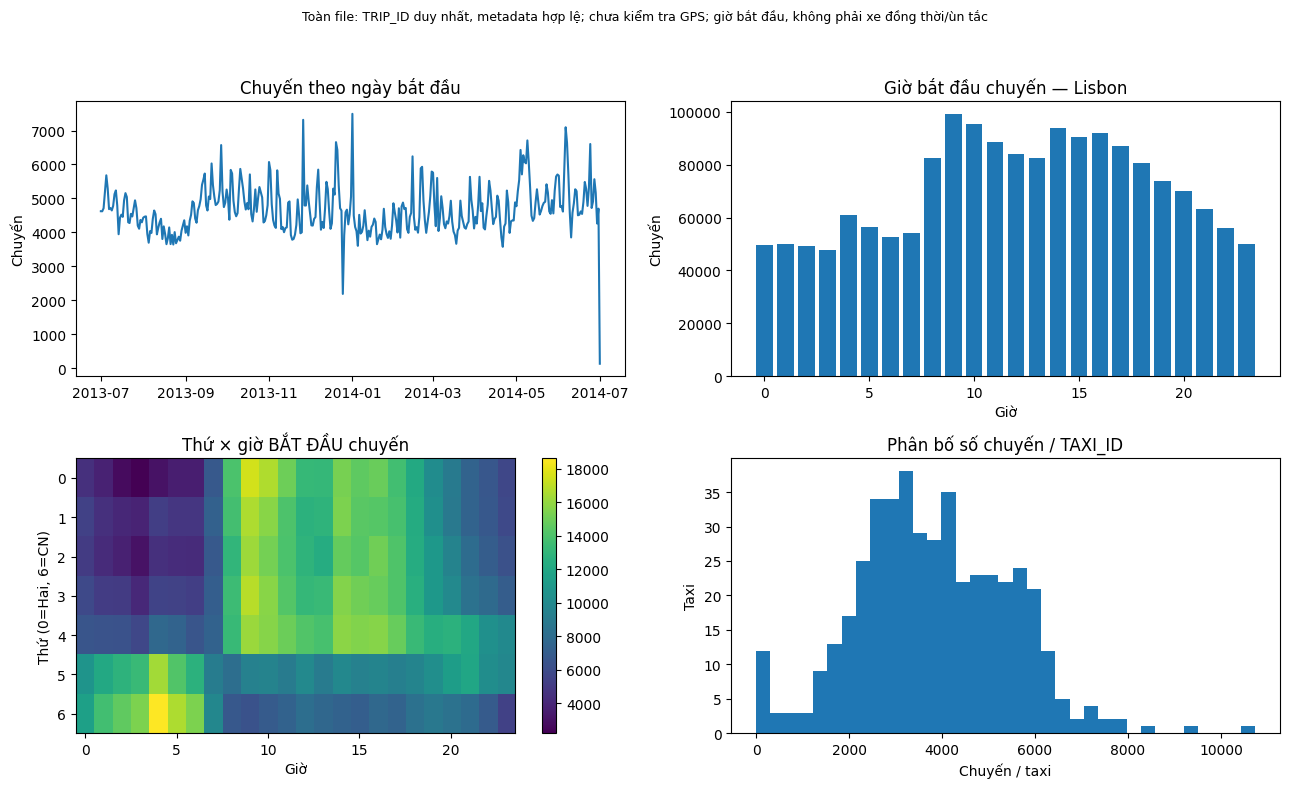

,call_type,trips,scope
0,A,364769,"Toàn file: TRIP_ID duy nhất, metadata hợp lệ; ..."
1,B,817878,"Toàn file: TRIP_ID duy nhất, metadata hợp lệ; ..."
2,C,527932,"Toàn file: TRIP_ID duy nhất, metadata hợp lệ; ..."


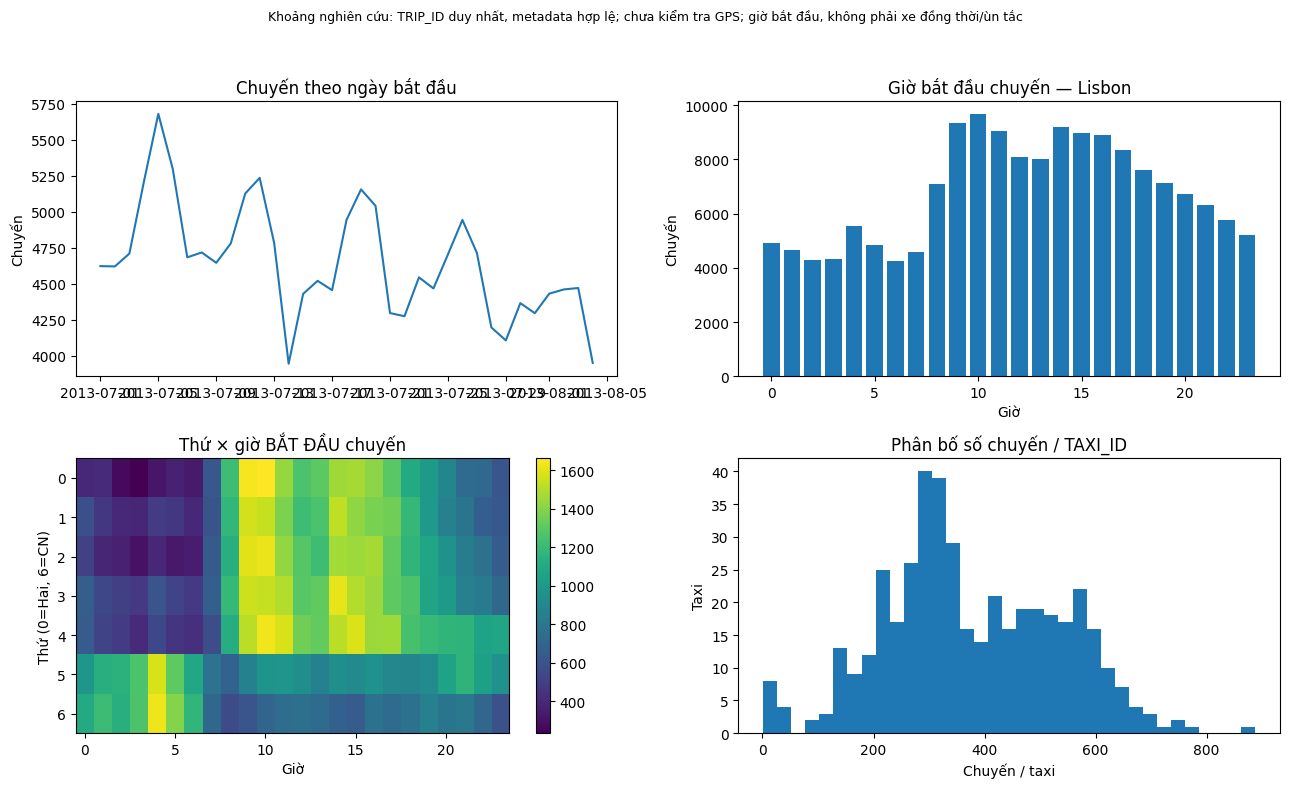

,call_type,trips,scope
0,A,33766,"Khoảng nghiên cứu: TRIP_ID duy nhất, metadata ..."
1,B,82274,"Khoảng nghiên cứu: TRIP_ID duy nhất, metadata ..."
2,C,46763,"Khoảng nghiên cứu: TRIP_ID duy nhất, metadata ..."


[metadata] complete: 1,710,670 dòng; metadata lưu trên SQLite.
metadata_scan_and_eda: 15.9s; RSS cuối bước=198.2 MiB (không phải peak)


In [5]:
DATA_PATH=ROOT/CFG["data_path"]
DB=META_REPORT=META_KEY=META_TABLES=None
if DATA_PATH.exists():
    with timed("metadata_scan_and_eda"):
        FINGERPRINT=input_fingerprint(DATA_PATH)
        DB,META_REPORT,META_KEY=metadata_database(DATA_PATH,FINGERPRINT)
        META_TABLES=metadata_eda(DB,META_REPORT)
        write_json(RUN/"data_source.json",{"path":str(DATA_PATH),"fingerprint":FINGERPRINT,
                   "dataset":"Kaggle ECML/PKDD 15 Taxi Trajectory Prediction I, train.csv"})
        status("metadata","complete",f"{META_REPORT['counts']['raw_rows']:,} dòng; metadata lưu trên SQLite.")
else:
    status("metadata","blocked",f"Thiếu {DATA_PATH}; sửa CFG['data_path'] ở cell A.")

## D. Lấy mẫu phân tầng ngày × giờ bắt đầu

Ngân sách mặc định: 35% sáng, 35% chiều, 30% ngoài cao điểm. Trong mỗi nhóm, phân bổ
quota gần đều giữa các ngày, giới hạn bởi số chuyến sẵn có. Nếu thiếu, phân bổ phần
còn lại và lưu quota_requested/quota_selected. Priority SHA256(seed, TRIP_ID) giúp
chọn mẫu tái lập, không phụ thuộc head(N). Fraction = quota tầng / số chuyến tầng.
Sau làm sạch GPS, tỷ lệ giữ lại có thể khác 70/30; không tự bù thêm rồi che giấu hao hụt.
Các bảng trước/sau ở đây so sánh **metadata hợp lệ trong khoảng khảo sát** với mẫu chọn.

In [6]:
def allocate(capacities,weights,budget):
    cap=pd.Series(capacities,dtype="int64"); weight=pd.Series(weights,index=cap.index,dtype=float)
    quota=pd.Series(0,index=cap.index,dtype="int64"); remaining=min(int(budget),int(cap.sum()))
    while remaining>0:
        available=cap-quota; eligible=available>0
        w=weight.where(eligible,0)
        if w.sum()<=0: w=eligible.astype(float)
        ideal=remaining*w/w.sum()
        add=np.minimum(np.floor(ideal).astype(int),available)
        if add.sum()==0:
            choices=ideal[eligible].sort_values(ascending=False,kind="stable").index
            for key in choices[:remaining]: add.loc[key]=1
        quota+=add; remaining-=int(add.sum())
    return quota

def make_selection(db,meta_key):
    sample_spec={k:CFG[k] for k in ["study_start","study_end","seed","sample_trips","peak_fraction","morning_share_of_peak"]}
    key=digest([meta_key,sample_spec,stage_hash("sampling")])[:20]
    folder=CACHE/"samples"/key; folder.mkdir(parents=True,exist_ok=True)
    marker=folder/"complete.json"
    if marker.exists() and not CFG["force_sample"]:
        return pd.read_parquet(folder/"selected.parquet"),pd.read_parquet(folder/"strata.parquet"),pd.read_parquet(folder/"quota_groups.parquet"),key
    marker.unlink(missing_ok=True)
    with contextlib.closing(sqlite3.connect(db)) as con:
        strata=pd.read_sql_query("SELECT day,period,COUNT(*) population FROM trips WHERE status='metadata_valid' AND timestamp>=? AND timestamp<? GROUP BY day,period ORDER BY day,period",con,params=[int(START.timestamp()),int(END.timestamp())])
        if strata.empty: raise ValueError("Không có metadata hợp lệ trong khoảng khảo sát.")
        groups=["morning_peak","evening_peak","off_peak"]
        weights=pd.Series([CFG["peak_fraction"]*CFG["morning_share_of_peak"],CFG["peak_fraction"]*(1-CFG["morning_share_of_peak"]),1-CFG["peak_fraction"]],index=groups)
        capacities=strata.groupby("period").population.sum().reindex(groups,fill_value=0)
        budget=min(CFG["sample_trips"],int(capacities.sum()))
        requested=allocate(pd.Series(budget,index=groups),weights,budget)
        group_quota=allocate(capacities,weights,budget)
        strata["quota"]=0
        for group in groups:
            mask=strata.period==group
            strata.loc[mask,"quota"]=allocate(strata.loc[mask,"population"],pd.Series(1.,index=strata.index[mask]),group_quota[group]).values
        strata["sampling_fraction"]=strata.quota/strata.population
        con.create_function("sample_priority",1,lambda value:digest([CFG["seed"],str(value)]))
        chunks=[]
        for row in strata.itertuples():
            if row.quota:
                chunk=pd.read_sql_query("SELECT trip_id,taxi_id,timestamp,day,weekday,hour,period,call_type,source_row FROM trips WHERE day=? AND period=? AND status='metadata_valid' AND timestamp>=? AND timestamp<? ORDER BY sample_priority(trip_id),trip_id LIMIT ?",con,
                    params=[row.day,row.period,int(START.timestamp()),int(END.timestamp()),int(row.quota)])
                chunk["sampling_fraction"]=row.sampling_fraction
                chunks.append(chunk)
        selected=pd.concat(chunks,ignore_index=True).sort_values("source_row").reset_index(drop=True)
        groups_table=pd.DataFrame({"period":groups,"population":capacities.values,"quota_requested":requested.values,
            "quota_selected":group_quota.values,"reallocated":(group_quota-requested).values})
    assert selected.trip_id.is_unique and len(selected)==budget
    save_table(selected,folder/"selected.parquet",csv=False)
    save_table(strata,folder/"strata.parquet",csv=False); save_table(groups_table,folder/"quota_groups.parquet",csv=False)
    write_json(marker,{"key":key,"spec":sample_spec,"sampled_trips":len(selected)})
    return selected,strata,groups_table,key

def sample_comparisons(selected,db):
    with contextlib.closing(sqlite3.connect(db)) as con:
        for name,keys in [("day",["day"]),("weekday",["weekday"]),("period",["period"]),("taxi",["taxi_id"])]:
            fields=",".join(keys)
            population=pd.read_sql_query(f"SELECT {fields},COUNT(*) population_trips FROM trips WHERE status='metadata_valid' AND timestamp>=? AND timestamp<? GROUP BY {fields}",con,params=[int(START.timestamp()),int(END.timestamp())])
            sample=selected.groupby(keys,as_index=False).agg(sample_trips=("trip_id","nunique"))
            table=population.merge(sample,on=keys,how="left").fillna({"sample_trips":0})
            table["population_share"]=table.population_trips/table.population_trips.sum()
            table["sample_share"]=table.sample_trips/max(1,table.sample_trips.sum())
            table["sampling_fraction"]=table.sample_trips/table.population_trips
            save_table(table,RUN/f"sample_compare_{name}.parquet","So sánh population metadata trong kỳ và mẫu chọn trước làm sạch GPS")
            if name!="taxi": display(table)
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    sample=pd.crosstab(selected.day,selected.period).reindex(columns=["morning_peak","evening_peak","off_peak"],fill_value=0)
    sample.plot.bar(stacked=True,ax=axes[0],width=.9); axes[0].tick_params(axis="x",labelsize=6)
    axes[0].set(title="Chuyến mẫu theo ngày và nhóm giờ BẮT ĐẦU",ylabel="Chuyến")
    selected.groupby("taxi_id").size().plot.hist(bins=25,ax=axes[1]); axes[1].set(title="Chuyến mẫu / taxi",xlabel="Chuyến / taxi")
    figure("sampling_distribution","Mẫu ưu tiên cao điểm trước lọc GPS; không dùng suy ra nhu cầu toàn thành phố")

,day,population_trips,sample_trips,population_share,sample_share,sampling_fraction
0,2013-07-01,4622,286,0.028390,0.0286,0.061878
1,2013-07-02,4620,286,0.028378,0.0286,0.061905
2,2013-07-03,4709,286,0.028925,0.0286,0.060735
3,2013-07-04,5206,286,0.031977,0.0286,0.054937
4,2013-07-05,5680,286,0.034889,0.0286,0.050352
5,2013-07-06,5296,286,0.032530,0.0286,0.054003
6,2013-07-07,4683,286,0.028765,0.0286,0.061072
7,2013-07-08,4717,286,0.028974,0.0286,0.060632
8,2013-07-09,4645,286,0.028531,0.0286,0.061572
9,2013-07-10,4779,286,0.029354,0.0286,0.059845


,weekday,population_trips,sample_trips,population_share,sample_share,sampling_fraction
0,0,22148,1429,0.136042,0.1429,0.064520
1,1,22694,1429,0.139395,0.1429,0.062968
2,2,22705,1429,0.139463,0.1429,0.062938
3,3,24410,1429,0.149936,0.1429,0.058542
4,4,25473,1428,0.156465,0.1428,0.056059
5,5,24304,1428,0.149285,0.1428,0.058756
6,6,21069,1428,0.129414,0.1428,0.067777


,period,population_trips,sample_trips,population_share,sample_share,sampling_fraction
0,evening_peak,24846,3500,0.152614,0.35,0.140868
1,morning_peak,11666,3500,0.071657,0.35,0.300017
2,off_peak,126291,3000,0.775729,0.30,0.023755


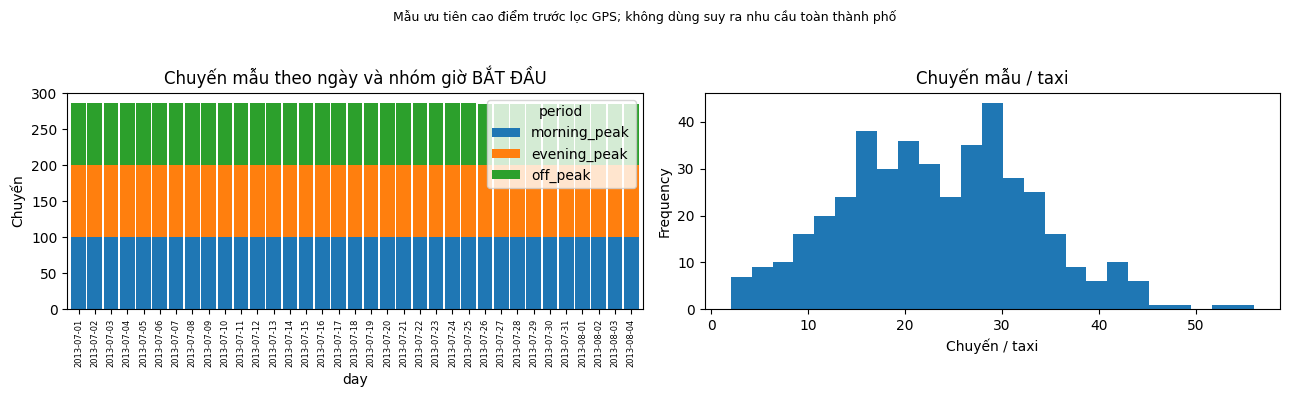

,period,population,quota_requested,quota_selected,reallocated
0,morning_peak,11666,3500,3500,0
1,evening_peak,24846,3500,3500,0
2,off_peak,126291,3000,3000,0


[sampling] complete: 10,000 chuyến, 35 ngày; seed=313.
stratified_sampling: 1.5s; RSS cuối bước=223.0 MiB (không phải peak)


In [7]:
SELECTED=STRATA=SAMPLE_KEY=None
if DB is not None:
    with timed("stratified_sampling"):
        SELECTED,STRATA,GROUP_QUOTAS,SAMPLE_KEY=make_selection(DB,META_KEY)
        save_table(SELECTED,RUN/"selected_trips.parquet","Mẫu chọn trước kiểm tra GPS",csv=False)
        save_table(STRATA,RUN/"sampling_strata.parquet","Population metadata trong kỳ và quota mẫu theo ngày × giờ bắt đầu")
        save_table(GROUP_QUOTAS,RUN/"sampling_group_quotas.parquet","Ngân sách mẫu theo giờ bắt đầu; không phải nhu cầu toàn dân")
        sample_comparisons(SELECTED,DB); display(GROUP_QUOTAS)
        if GROUP_QUOTAS.reallocated.ne(0).any(): print("Có tầng thiếu chuyến; xem reallocated trong bảng quota.")
        status("sampling","complete",f"{len(SELECTED):,} chuyến, {SELECTED.day.nunique()} ngày; seed={CFG['seed']}.")
else: status("sampling","blocked","Cần dữ liệu metadata.")

## E. Parse và làm sạch GPS mẫu

Thời gian được gắn bằng **timestamp bắt đầu + 15 × original_index** trước khi lọc.
Khi điểm sai, vượt kiểm tra địa lý rộng, vượt kỳ khảo sát hoặc tạo bước nhảy bất thường,
các đoạn được tách; không nối hai đầu qua khoảng mất điểm. Giữ các điểm đứng yên.
Chuyến MISSING_DATA=True bị loại ở metadata và được kiểm tra lại ở đây.

Quãng đường là tổng khoảng cách geodesic giữa GPS liên tiếp trong các đoạn giữ lại,
**chưa phải quãng đường trên mạng đường**. Thời lượng giữ lại là tổng thời gian các
đoạn liên tục, không cộng thời gian bị mất. Endpoint map chỉ dùng điểm gốc index=0
hoặc index cuối, không lấy đầu/cuối của đoạn đã cắt để giả làm đầu/cuối chuyến.

In [8]:
def clean_gps(polyline,trip_timestamp,trip_id="trip",taxi_id="taxi",missing_flag=False):
    stats={"raw_points":0,"kept_points":0,"invalid_coordinates":0,"outside_broad_geography":0,
           "outside_study_time":0,"jump_links":0,"short_segment_points":0,"n_segments":0,
           "raw_duration_s":0.,"retained_duration_s":0.,"gps_distance_m":0.,"reason":"retained"}
    if str(missing_flag).strip().lower() in ["true","1"]:
        stats["reason"]="missing_data_true"; return [],stats
    try:
        coordinates=json.loads(polyline)
    except (ValueError,TypeError):
        stats["reason"]="invalid_json"; return [],stats
    if not isinstance(coordinates,list):
        stats["reason"]="invalid_polyline"; return [],stats
    stats["raw_points"]=len(coordinates)
    stats["raw_duration_s"]=max(0,len(coordinates)-1)*CFG["gps_interval_s"]
    if len(coordinates)<CFG["min_trip_points"]:
        stats["reason"]="empty_or_short_trip"; return [],stats
    west,south,east,north=CFG["broad_geo_bbox"]
    valid=[]
    for original_index,pair in enumerate(coordinates):
        timestamp=int(trip_timestamp)+CFG["gps_interval_s"]*original_index
        try:
            if not isinstance(pair,(list,tuple)) or len(pair)!=2: raise ValueError("coordinate shape")
            lon,lat=map(float,pair)
            if not np.isfinite([lon,lat]).all() or not (-180<=lon<=180 and -90<=lat<=90): raise ValueError("coordinate range")
        except (TypeError,ValueError,OverflowError):
            stats["invalid_coordinates"]+=1; continue
        if not (west<=lon<=east and south<=lat<=north):
            stats["outside_broad_geography"]+=1; continue
        if not (START.timestamp()<=timestamp<END.timestamp()):
            stats["outside_study_time"]+=1; continue
        valid.append({"trip_id":str(trip_id),"taxi_id":str(taxi_id),"original_index":original_index,
                      "timestamp":timestamp,"lon":lon,"lat":lat})
    segments=[]; segment=[]
    for point in valid:
        if segment:
            previous=segment[-1]
            distance=GEOD.inv(previous["lon"],previous["lat"],point["lon"],point["lat"])[2]
            dt=point["timestamp"]-previous["timestamp"]
            discontinuity=point["original_index"]!=previous["original_index"]+1
            jumping=distance/dt*3.6>CFG["max_gps_speed_kmh"]
            if discontinuity or jumping:
                stats["jump_links"]+=int(jumping and not discontinuity)
                if len(segment)>=CFG["min_segment_points"]: segments.append(segment)
                else: stats["short_segment_points"]+=len(segment)
                segment=[]
        segment.append(point)
    if segment:
        if len(segment)>=CFG["min_segment_points"]: segments.append(segment)
        else: stats["short_segment_points"]+=len(segment)
    if sum(map(len,segments))<CFG["min_trip_points"]:
        stats["reason"]="too_few_retained_points"; return [],stats
    kept=[]
    for number,part in enumerate(segments):
        for point in part:
            point["segment_id"]=f"{trip_id}:seg{number}"
            point["is_original_start"]=point["original_index"]==0
            point["is_original_end"]=point["original_index"]==len(coordinates)-1
            kept.append(point)
        for left,right in zip(part[:-1],part[1:]):
            assert right["original_index"]==left["original_index"]+1
            stats["gps_distance_m"]+=GEOD.inv(left["lon"],left["lat"],right["lon"],right["lat"])[2]
            stats["retained_duration_s"]+=right["timestamp"]-left["timestamp"]
    stats["kept_points"]=len(kept); stats["n_segments"]=len(segments)
    return kept,stats

POINT_COLUMNS=["trip_id","taxi_id","original_index","timestamp","lon","lat","segment_id","is_original_start","is_original_end","x","y"]

def clean_selected(path,selected,sample_key):
    clean_spec={k:CFG[k] for k in ["gps_interval_s","min_trip_points","min_segment_points","max_gps_speed_kmh","broad_geo_bbox","metric_crs"]}
    key=digest([sample_key,clean_spec,stage_hash("cleaning")])[:20]
    folder=CACHE/"clean"/key; folder.mkdir(parents=True,exist_ok=True)
    marker=folder/"complete.json"
    if marker.exists() and not CFG["force_clean"]:
        audit=pd.read_parquet(folder/"trip_audit.parquet")
        paths=[folder/name for name in json.loads(marker.read_text(encoding="utf-8"))["point_files"]]
        points=pd.concat([pd.read_parquet(p) for p in paths],ignore_index=True) if paths else pd.DataFrame(columns=POINT_COLUMNS)
        return audit,points,key,folder
    marker.unlink(missing_ok=True)
    targets=selected.set_index("source_row"); wanted=set(targets.index.astype(int)); seen=set()
    audits=[]; files=[]; batch_number=0; offset=0; original_rows=[]
    with input_stream(path,CFG["zip_member"]) as stream:
        for chunk in pd.read_csv(stream,usecols=["TRIP_ID","TAXI_ID","TIMESTAMP","POLYLINE","MISSING_DATA"],dtype="string",chunksize=CFG["chunk_size"]):
            batch_points=[]
            positions=[i for i in range(len(chunk)) if offset+i in wanted]
            for position in positions:
                row=chunk.iloc[position]; source_row=offset+position; seen.add(source_row)
                expected=targets.loc[source_row]
                if str(row.TRIP_ID)!=expected.trip_id: raise RuntimeError("CSV thay đổi so với metadata cache; bật force_metadata/verify_full_hash.")
                points,report=clean_gps(row.POLYLINE,int(row.TIMESTAMP),str(row.TRIP_ID),str(row.TAXI_ID),row.MISSING_DATA)
                audits.append({**expected.to_dict(),"source_row":source_row,**report})
                original_rows.append({"trip_id":str(row.TRIP_ID),"taxi_id":str(row.TAXI_ID),"timestamp":int(row.TIMESTAMP),
                                      "polyline":row.POLYLINE,"scope":"Mẫu chọn trước làm sạch GPS"})
                batch_points.extend(points)
            if batch_points:
                frame=pd.DataFrame(batch_points)
                frame["x"],frame["y"]=PROJECT.transform(frame.lon.to_numpy(),frame.lat.to_numpy())
                name=f"points_{batch_number:05d}.parquet"; save_table(frame,folder/name,csv=False)
                files.append(name); batch_number+=1
            offset+=len(chunk)
            if len(seen)==len(wanted): break
    if seen!=wanted: raise RuntimeError("Không tìm thấy đủ source_row được chọn trong CSV.")
    audit=pd.DataFrame(audits); save_table(audit,folder/"trip_audit.parquet",csv=False)
    save_table(pd.DataFrame(original_rows),folder/"sample_raw_trips.parquet",csv=False)
    write_json(marker,{"key":key,"point_files":files,"selected_trips":len(selected),"spec":clean_spec})
    points=pd.concat([pd.read_parquet(folder/name) for name in files],ignore_index=True) if files else pd.DataFrame(columns=POINT_COLUMNS)
    return audit,points,key,folder

def gps_eda(audit,points,clean_folder):
    kept=audit[audit.kept_points>0]
    summary=pd.DataFrame([
        {"stage":"sample_before_cleaning","trips":len(audit),"taxis":audit.taxi_id.nunique(),"start_days":audit.day.nunique(),"gps_points":int(audit.raw_points.sum())},
        {"stage":"sample_after_cleaning","trips":len(kept),"taxis":kept.taxi_id.nunique(),"start_days":kept.day.nunique(),"gps_points":len(points)},
    ])
    save_table(audit,RUN/"sample_cleaning_audit.parquet","Mẫu được chọn; reason và số GPS trước/sau lọc",csv=False)
    save_table(summary,RUN/"gps_cleaning_summary.parquet","Chỉ mẫu chọn, không phải toàn file")
    reasons=audit.groupby("reason").size().rename("trips").reset_index()
    save_table(reasons,RUN/"gps_trip_removal_reasons.parquet","Mẫu được chọn")
    diagnostics=audit[["invalid_coordinates","outside_broad_geography","outside_study_time","jump_links","short_segment_points"]].sum().rename("count").rename_axis("diagnostic").reset_index()
    save_table(diagnostics,RUN/"gps_point_diagnostics.parquet","Mẫu; jump_links đếm liên kết, các cột còn lại đếm điểm")
    display(summary); display(reasons); display(diagnostics)
    distribution=audit[["raw_points","kept_points","raw_duration_s","retained_duration_s","gps_distance_m"]].describe(percentiles=[.1,.5,.9,.99]).reset_index()
    save_table(distribution,RUN/"gps_sample_distributions.parquet","Mẫu; GPS distance nối điểm, chưa phải quãng đường mạng đường")
    display(distribution)
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    axes[0].hist(audit.raw_points,bins=40,alpha=.5,label="Trước lọc"); axes[0].hist(audit.kept_points,bins=40,alpha=.5,label="Sau lọc")
    axes[0].set(title="GPS / chuyến",yscale="log"); axes[0].legend()
    axes[1].hist(kept.retained_duration_s/60,bins=40); axes[1].set(title="Thời lượng giữ lại",xlabel="Phút")
    axes[2].hist(kept.gps_distance_m/1000,bins=40); axes[2].set(title="Quãng đường nối GPS",xlabel="km; chưa phải khoảng cách mạng đường")
    figure("gps_cleaning_distributions",SCOPE_SAMPLE)
    cleaned_groups=points.groupby("trip_id",sort=False) if not points.empty else None
    raw=pd.read_parquet(clean_folder/"sample_raw_trips.parquet")
    # Ưu tiên gồm cả ví dụ có điểm bị loại để QA; đây không phải tự chọn vùng nghiên cứu.
    ids=audit.sort_values(["jump_links","invalid_coordinates","outside_broad_geography"],ascending=False).head(3).trip_id.tolist()
    ids+=audit[audit.kept_points>0].sample(min(3,len(kept)),random_state=CFG["seed"]).trip_id.tolist()
    ids=list(dict.fromkeys(ids))[:6]
    if ids:
        fig,axes=plt.subplots(2,3,figsize=(14,8))
        for ax,trip_id in zip(axes.flat,ids):
            record=raw[raw.trip_id==trip_id].iloc[0]
            try: original=json.loads(record.polyline)
            except (ValueError,TypeError): original=[]
            if not isinstance(original,list): original=[]
            xs=[]; ys=[]
            for item in original:
                try:
                    a,b=map(float,item)
                    if not (-180<=a<=180 and -90<=b<=90): raise ValueError("range")
                    xs.append(a); ys.append(b)
                except (TypeError,ValueError): xs.append(np.nan); ys.append(np.nan)
            ax.plot(xs,ys,".--",color="gray",markersize=2,label="GPS gốc, có thể lỗi")
            if cleaned_groups is not None and trip_id in cleaned_groups.groups:
                for index,(_,part) in enumerate(cleaned_groups.get_group(trip_id).groupby("segment_id",sort=False)):
                    ax.plot(part.lon,part.lat,".-",markersize=2,label="Đoạn giữ lại" if index==0 else None)
            ax.set(title=trip_id[-20:],xlabel="Longitude",ylabel="Latitude"); ax.legend(fontsize=6)
        for ax in list(axes.flat)[len(ids):]: ax.set_visible(False)
        figure("gps_before_after_examples","GPS mẫu; đường nối chỉ là vệt quan sát, không phải đường OSM")

,stage,trips,taxis,start_days,gps_points
0,sample_before_cleaning,10000,428,35,488358
1,sample_after_cleaning,9793,426,35,487590


,reason,trips
0,empty_or_short_trip,207
1,retained,9793


,diagnostic,count
0,invalid_coordinates,0
1,outside_broad_geography,0
2,outside_study_time,18
3,jump_links,2028
4,short_segment_points,496


,index,raw_points,kept_points,raw_duration_s,retained_duration_s,gps_distance_m
0,count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
1,mean,48.835800,48.759000,717.588000,714.397500,5596.393310
2,std,42.980805,42.553418,644.654706,636.325841,6740.386459
3,min,0.000000,0.000000,0.000000,0.000000,0.000000
4,10%,19.000000,19.000000,270.000000,270.000000,1420.863129
5,50%,42.000000,42.000000,615.000000,615.000000,3949.783749
6,90%,81.000000,81.000000,1200.000000,1200.000000,11720.337058
7,99%,182.010000,182.010000,2715.150000,2700.150000,25078.042479
8,max,1857.000000,1857.000000,27840.000000,27810.000000,212588.047456


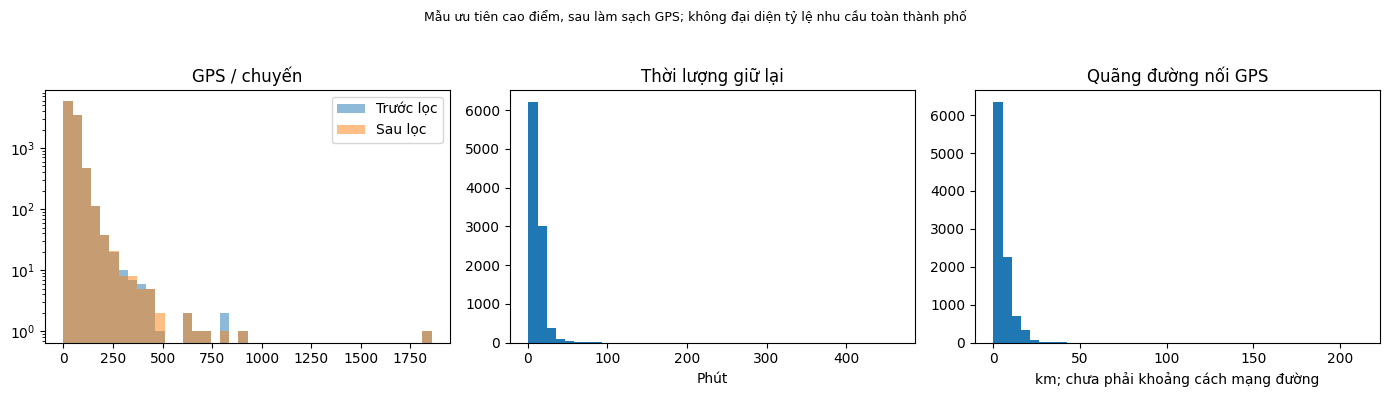

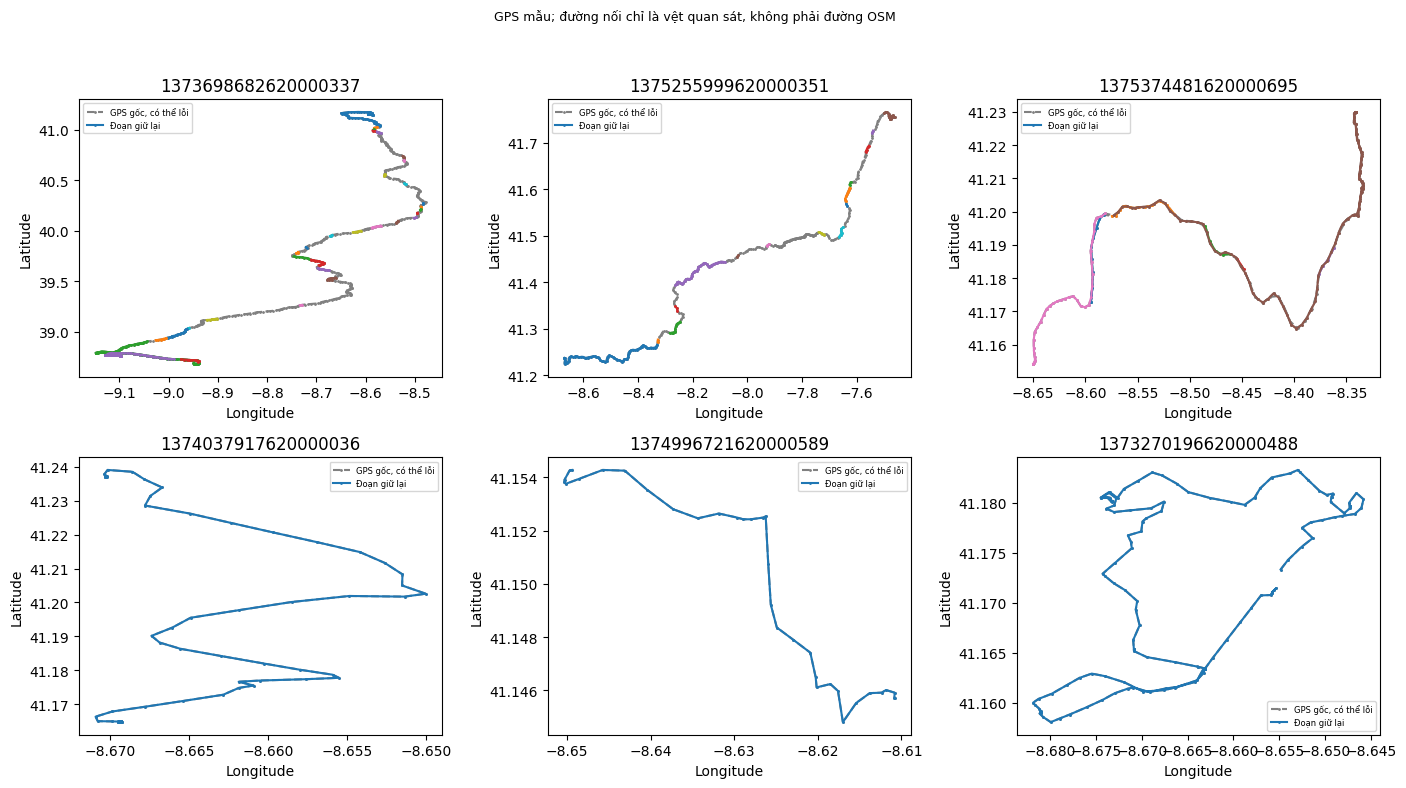

[gps] complete: 9,793 chuyến; 487,590 GPS mẫu giữ lại.
gps_sample_cleaning_and_eda: 3.6s; RSS cuối bước=320.8 MiB (không phải peak)


In [9]:
AUDIT=POINTS=CLEAN_KEY=CLEAN_FOLDER=None
if SELECTED is not None:
    with timed("gps_sample_cleaning_and_eda"):
        AUDIT,POINTS,CLEAN_KEY,CLEAN_FOLDER=clean_selected(DATA_PATH,SELECTED,SAMPLE_KEY)
        gps_eda(AUDIT,POINTS,CLEAN_FOLDER)
        if POINTS.empty: status("gps","blocked","Không có GPS hợp lệ sau lọc; xem audit và broad_geo_bbox.")
        else: status("gps","complete",f"{POINTS.trip_id.nunique():,} chuyến; {len(POINTS):,} GPS mẫu giữ lại.")
else: status("gps","blocked","Cần mẫu đã chọn.")

## F. Lưới mét và độ phủ theo thời gian của từng điểm

Dùng UTM 29N (EPSG:32629), ô mặc định 500m và anchor (0,0) cố định trong CRS.
cell_id chứa kích thước lưới, chỉ số x/y; đổi 250m hoặc 1.000m tạo cache lưới riêng.
Distinct trip/taxi/day được tính từ **thời gian từng điểm GPS**, không gán cả chuyến
vào giờ khởi hành. Một chuyến có 20 điểm trong cùng ô–giờ vẫn chỉ đếm là một chuyến.

Ô không có điểm trong mẫu có thể do mẫu nhỏ hoặc GPS thưa; không đồng nghĩa không có
taxi đi qua. Nhiều điểm đứng yên không được xem là nhiều chuyến độc lập. Các bảng này
mô tả quan sát mẫu đã ưu tiên cao điểm, không phải ước lượng trực tiếp nhu cầu thành phố.
Một chuyến có thể xuất hiện ở nhiều nhóm giờ; không cộng số chuyến các nhóm để ra tổng distinct.

In [10]:
def attach_grid(points,size):
    frame=point_time_columns(points)
    frame["gx"]=np.floor(frame.x/size).astype("int32"); frame["gy"]=np.floor(frame.y/size).astype("int32")
    frame["cell_id"]="g"+str(size)+"_"+frame.gx.astype(str)+"_"+frame.gy.astype(str)
    return frame

def count_observations(frame,keys):
    return frame.groupby(keys,as_index=False,observed=True).agg(n_trips=("trip_id","nunique"),
        n_taxis=("taxi_id","nunique"),n_days=("date","nunique"),n_points=("trip_id","size"))

def grid_statistics(frame):
    summary=count_observations(frame,["cell_id","gx","gy"])
    periods=count_observations(frame,["cell_id","period"])
    for label in ["morning_peak","evening_peak","off_peak"]:
        sub=periods[periods.period==label].drop(columns="period").rename(columns={c:label+"_"+c for c in ["n_trips","n_taxis","n_days","n_points"]})
        summary=summary.merge(sub,on="cell_id",how="left",validate="one_to_one")
    numeric=[c for c in summary if c not in ["cell_id","gx","gy"]]
    summary[numeric]=summary[numeric].fillna(0).astype(int)
    daily=count_observations(frame,["cell_id","date"])
    distribution=daily.groupby("cell_id",as_index=False).agg(daily_trips_median_observed=("n_trips","median"),daily_trips_max=("n_trips","max"),daily_trips_mean_observed=("n_trips","mean"))
    summary=summary.merge(distribution,on="cell_id",validate="one_to_one")
    cell_time=count_observations(frame,["cell_id","day_group","slot"])
    weekday_time=count_observations(frame,["cell_id","weekday","slot"])
    calendar_days=len(pd.date_range(START.tz_convert(CFG["timezone"]).normalize(),(END-pd.Timedelta(nanoseconds=1)).tz_convert(CFG["timezone"]).normalize(),freq="D"))
    summary["calendar_days_in_study"]=calendar_days
    summary["sample_unobserved_days"]=calendar_days-summary.n_days
    return summary,periods,daily,cell_time,weekday_time

def grid_geometries(summary,size):
    polygons=shapely.box(summary.gx.to_numpy()*size,summary.gy.to_numpy()*size,(summary.gx.to_numpy()+1)*size,(summary.gy.to_numpy()+1)*size)
    geo=gpd.GeoDataFrame(summary.copy(),geometry=polygons,crs=CFG["metric_crs"]).to_crs("EPSG:4326")
    bounds=geo.bounds
    geo["west"]=bounds.minx; geo["south"]=bounds.miny; geo["east"]=bounds.maxx; geo["north"]=bounds.maxy
    return geo

def build_grid(points,clean_key):
    grid_spec={k:CFG[k] for k in ["grid_size_m","time_bin_minutes","day_grouping","timezone","peak_windows","metric_crs"]}
    key=digest([clean_key,grid_spec,stage_hash("grid")])[:20]
    folder=CACHE/"grid"/key; folder.mkdir(parents=True,exist_ok=True)
    names=["cells","cell_period","cell_daily","cell_time","cell_weekday_time"]
    if (folder/"complete.json").exists() and not CFG["force_grid"]:
        frames={name:pd.read_parquet(folder/(name+".parquet")) for name in names}
        point_cells=pd.read_parquet(folder/"point_cells.parquet")
        geometry=gpd.read_parquet(folder/"cells_geometry.parquet")
        return frames,point_cells,geometry,key
    (folder/"complete.json").unlink(missing_ok=True)
    point_cells=attach_grid(points,CFG["grid_size_m"])
    frames=dict(zip(names,grid_statistics(point_cells)))
    geometry=grid_geometries(frames["cells"],CFG["grid_size_m"])
    for name,frame in frames.items(): save_table(frame,folder/(name+".parquet"),csv=False)
    save_table(point_cells,folder/"point_cells.parquet",csv=False)
    geometry.to_parquet(folder/"cells_geometry.parquet",index=False)
    write_json(folder/"complete.json",{"key":key,"spec":grid_spec,"n_cells":len(geometry),"n_points":len(points)})
    return frames,point_cells,geometry,key

In [11]:
GRID=POINT_CELLS=GRID_GEO=GRID_KEY=None
if POINTS is not None and not POINTS.empty:
    with timed("grid_coverage"):
        GRID,POINT_CELLS,GRID_GEO,GRID_KEY=build_grid(POINTS,CLEAN_KEY)
        for name,frame in GRID.items(): save_table(frame,RUN/f"grid_{name}.parquet",SCOPE_SAMPLE)
        GRID_GEO.assign(scope=SCOPE_SAMPLE).to_parquet(RUN/"grid_cells_geo.parquet",index=False)
        display(GRID["cells"].sort_values(["n_days","n_trips"],ascending=False).head(25).assign(scope=SCOPE_SAMPLE))
        status("grid","complete",f"{len(GRID_GEO):,} ô có GPS mẫu; ô không phải cạnh đường.")
else: status("grid","blocked","Cần GPS mẫu hợp lệ.")

,cell_id,gx,gy,n_trips,n_taxis,n_days,n_points,morning_peak_n_trips,morning_peak_n_taxis,morning_peak_n_days,...,off_peak_n_trips,off_peak_n_taxis,off_peak_n_days,off_peak_n_points,daily_trips_median_observed,daily_trips_max,daily_trips_mean_observed,calendar_days_in_study,sample_unobserved_days,scope
1167,g500_1065_9110,1065,9110,2814,410,35,24408,950,263,35,...,981,340,35,7903,77.0,111,80.400000,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1168,g500_1065_9111,1065,9111,1781,396,35,9823,531,235,35,...,658,310,35,3372,51.0,65,50.914286,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1035,g500_1063_9110,1063,9110,1727,397,35,10056,582,218,35,...,604,291,35,3395,49.0,69,49.342857,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1166,g500_1065_9109,1065,9109,1567,361,35,8412,520,205,35,...,503,239,35,2682,43.0,68,44.771429,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
978,g500_1062_9111,1062,9111,1501,381,35,9553,434,205,35,...,526,266,35,3188,41.0,61,42.885714,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1101,g500_1064_9109,1064,9109,1461,363,35,8653,336,175,35,...,568,261,35,2804,42.0,66,41.800000,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1170,g500_1065_9113,1065,9113,1414,370,35,7073,466,219,35,...,511,274,35,2557,41.0,53,40.400000,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
977,g500_1062_9110,1062,9110,1308,367,35,3048,391,190,35,...,460,246,35,1054,37.0,56,37.400000,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1102,g500_1064_9110,1064,9110,1305,368,35,8534,428,200,35,...,511,265,35,3702,34.0,66,37.314286,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."
1236,g500_1066_9115,1066,9115,1301,371,35,3452,479,228,35,...,442,247,35,1200,37.0,55,37.200000,35,0,"Mẫu ưu tiên cao điểm, sau làm sạch GPS; không ..."


[grid] complete: 3,516 ô có GPS mẫu; ô không phải cạnh đường.
grid_coverage: 0.9s; RSS cuối bước=392.9 MiB (không phải peak)


## G. Bản đồ quan sát mẫu — dùng để tự xem, không phải bản đồ ùn tắc

Mở `maps/01_grid_distinct_trips.html` để xem số chuyến khác nhau trong từng ô, rồi đối
chiếu `02_morning_peak`, `03_evening_peak`, `04_off_peak`, `05_observed_days`.
Tooltip ghi ranh giới lon/lat, trip/taxi/day và ba nhóm giờ của từng điểm.
`06_trip_endpoints.html` chỉ thể hiện đầu/cuối chuyến, tách khỏi bản đồ toàn vệt GPS.
`07_sample_trajectories.html` chỉ có ít chuyến minh họa, không nối qua khoảng mất điểm.

Khi số ô vượt giới hạn hiển thị, HTML chỉ hiển thị các ô nhiều quan sát nhất và ghi số
bị lược; GeoParquet/CSV và PNG toàn phạm vi vẫn giữ toàn bộ ô. Đây là giới hạn hiển thị,
không phải chọn vùng thay bạn. Không dùng tile đường nền để đếm cạnh đường.

In [12]:
MAP_REPORT=[]

def map_base(title,center=None):
    map_object=folium.Map(location=center or CFG["map_center"],zoom_start=CFG["map_zoom"],tiles=CFG["map_tiles"],prefer_canvas=True)
    banner=("<div style='position:fixed;top:8px;left:55px;z-index:9999;background:white;padding:7px;max-width:650px;font-size:12px'>"
            +html.escape(title)+"<br><b>MẪU GPS ưu tiên cao điểm — mật độ/độ phủ quan sát, không phải ùn tắc.</b></div>")
    map_object.get_root().html.add_child(folium.Element(banner))
    folium.LatLngPopup().add_to(map_object)
    return map_object

def add_boundaries(map_object,regions):
    for region in regions:
        west,south,east,north=region["bbox"]
        folium.Rectangle([[south,west],[north,east]],color="purple",weight=3,fill=False,
                         tooltip=html.escape(region["name"])).add_to(map_object)

def draw_grid_map(geo,column,name,title,regions=None,center=None):
    # PNG luôn tạo: dùng tọa độ mét; mọi ô có quan sát đều được giữ.
    if not geo.empty:
        fig,ax=plt.subplots(figsize=(9,8))
        projected=geo.to_crs(CFG["metric_crs"])
        projected.assign(log_value=np.log1p(projected[column].fillna(0))).plot(column="log_value",ax=ax,legend=True,cmap="YlOrRd",linewidth=0)
        ax.set(title=title+"; màu log(1+giá trị)",xlabel="UTM easting (m)",ylabel="UTM northing (m)")
        if regions:
            for region in regions:
                boundary=gpd.GeoSeries([box(*region["bbox"])],crs=4326).to_crs(CFG["metric_crs"])
                boundary.boundary.plot(ax=ax,color="purple",linewidth=1)
        figure(name,SCOPE_SAMPLE)
        # Khung nhìn trung tâm giúp xem Porto khi có một số chuyến đi rất xa.
        # Mọi ô vẫn nằm trong bảng/HTML/PNG toàn phạm vi; đây không phải vùng được chọn.
        cx,cy=PROJECT.transform(CFG["map_center"][1],CFG["map_center"][0]); radius=CFG["static_view_radius_m"]
        west,south=UNPROJECT.transform(cx-radius,cy-radius); east,north=UNPROJECT.transform(cx+radius,cy+radius)
        fig,ax=plt.subplots(figsize=(9,8))
        geo.assign(log_value=np.log1p(geo[column].fillna(0))).plot(column="log_value",ax=ax,legend=True,cmap="YlOrRd",linewidth=0)
        ax.set(xlim=(west,east),ylim=(south,north),title=title+"; khung nhìn quanh tâm hiển thị",
               xlabel="Longitude",ylabel="Latitude")
        if regions:
            gpd.GeoSeries([box(*r["bbox"]) for r in regions],crs=4326).boundary.plot(ax=ax,color="purple",linewidth=1)
        figure(name+"_porto_view",SCOPE_SAMPLE+"; chỉ đổi khung nhìn, không lọc GPS hoặc chọn vùng")
    if not HAS_FOLIUM:
        MAP_REPORT.append({"map":name,"html":"not_available_missing_folium","png":True}); return None
    rendered=geo.sort_values(column,ascending=False).head(CFG["max_map_cells"]).copy()
    limit_note=f"Hiển thị {len(rendered):,}/{len(geo):,} ô có dữ liệu trong bảng; không hiện điểm = chưa biết, không phải đường trống."
    m=map_base(title+". "+limit_note,center)
    if not rendered.empty:
        fields=["cell_id","west","south","east","north","n_trips","n_taxis","n_days","n_points"]
        fields += [period+"_"+field for period in ["morning_peak","evening_peak","off_peak"] for field in ["n_trips","n_taxis","n_days"]]
        fields=[c for c in fields if c in rendered]
        upper=max(1.,float(np.log1p(rendered[column].max())))
        scale=bcm.LinearColormap(["#ffffcc","#fed976","#fd8d3c","#e31a1c","#800026"],vmin=0,vmax=upper)
        payload=json.loads(rendered[fields+["geometry"]].assign(color_value=rendered[column]).to_json(drop_id=True,na="null"))
        folium.GeoJson(payload,name=title,style_function=lambda feature:{"fillColor":scale(np.log1p(feature["properties"]["color_value"])),
            "color":"#555555","weight":.3,"fillOpacity":.65},
            tooltip=folium.GeoJsonTooltip(fields=fields,localize=True,sticky=False),
            highlight_function=lambda feature:{"weight":2,"color":"#222222","fillOpacity":.85}).add_to(m)
        scale.caption=title+" — log(1+giá trị), không phải mức ùn tắc"; scale.add_to(m)
    add_boundaries(m,regions or [])
    m.save(str(MAPS/(name+".html")))
    MAP_REPORT.append({"map":name,"all_cells":len(geo),"rendered_cells":len(rendered),
                       "omitted_from_html":len(geo)-len(rendered),"scope":SCOPE_SAMPLE})
    return m

def endpoint_maps(points):
    endpoints=points[points.is_original_start|points.is_original_end].copy()
    save_table(endpoints,RUN/"sample_trip_endpoints.parquet",SCOPE_SAMPLE,csv=False)
    summary=[]
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    m=map_base("Điểm đầu/cuối chuyến gốc; hiển thị mẫu tối đa 3.000 điểm mỗi loại") if HAS_FOLIUM else None
    for ax,column,label,color in zip(axes,["is_original_start","is_original_end"],["Đầu chuyến","Cuối chuyến"],["green","red"]):
        frame=endpoints[endpoints[column]]
        summary.append({"endpoint":label,"n_points":len(frame),"n_trips":frame.trip_id.nunique()})
        ax.scatter(frame.lon,frame.lat,s=1,alpha=.15,c=color); ax.set(title=label,xlabel="Longitude",ylabel="Latitude")
        if m is not None:
            from folium.plugins import FastMarkerCluster
            displayed=frame.sample(min(3000,len(frame)),random_state=CFG["seed"])
            FastMarkerCluster(displayed[["lat","lon"]].to_numpy().tolist(),name=label).add_to(m)
    figure("06_trip_endpoints",SCOPE_SAMPLE+"; đầu/cuối chuyến gốc, không phải đầu/cuối đoạn sau lọc")
    save_table(pd.DataFrame(summary),RUN/"endpoint_counts.parquet",SCOPE_SAMPLE)
    if m is not None:
        folium.LayerControl().add_to(m); m.save(str(MAPS/"06_trip_endpoints.html"))

def trajectory_map(points):
    if not HAS_FOLIUM: return
    trips=pd.Series(points.trip_id.unique()).sample(min(CFG["trajectory_examples"],points.trip_id.nunique()),random_state=CFG["seed"]).tolist()
    m=map_base(f"Vệt GPS mẫu minh họa: {len(trips)} chuyến; mỗi đoạn liên tục vẽ riêng")
    palette=["blue","red","green","orange","purple","darkred"]
    for index,trip_id in enumerate(trips):
        layer=folium.FeatureGroup(name="Trip "+str(trip_id),show=True)
        for segment_id,segment in points[points.trip_id==trip_id].groupby("segment_id",sort=False):
            segment=segment.sort_values("original_index")
            folium.PolyLine(segment[["lat","lon"]].to_numpy().tolist(),color=palette[index%len(palette)],weight=2,
                            tooltip=html.escape(str(segment_id))).add_to(layer)
        layer.add_to(m)
    folium.LayerControl(collapsed=True).add_to(m); m.save(str(MAPS/"07_sample_trajectories.html"))

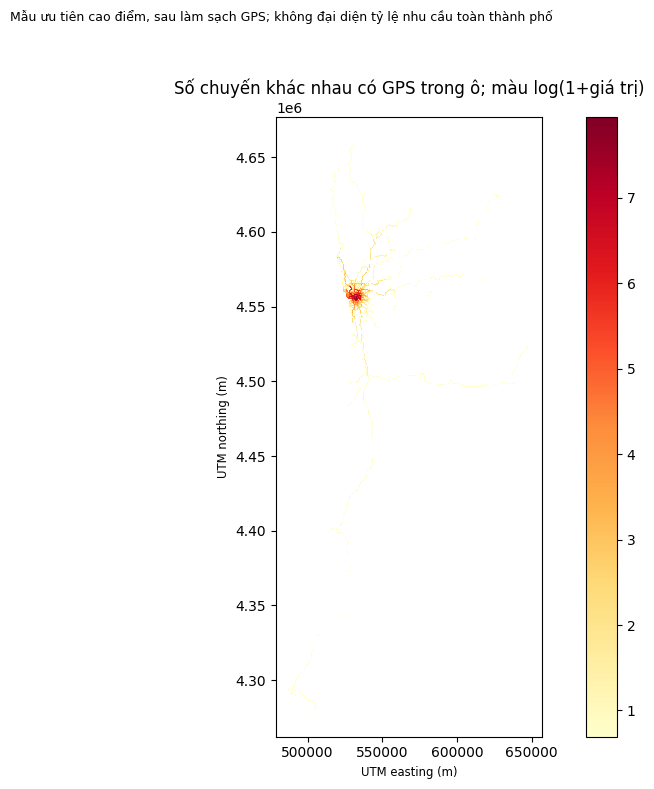

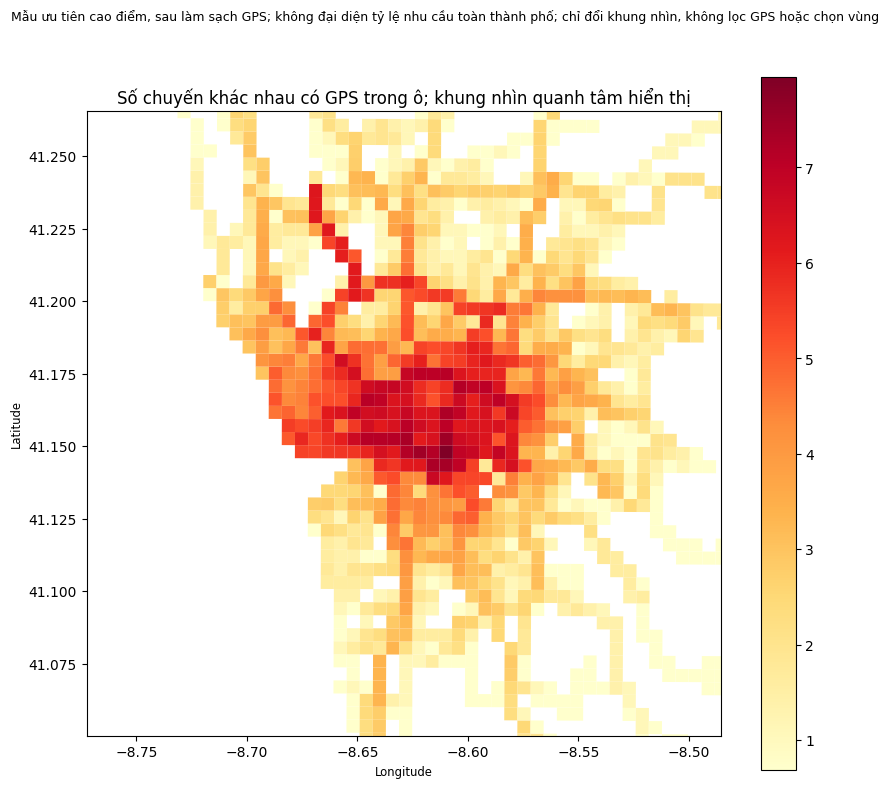

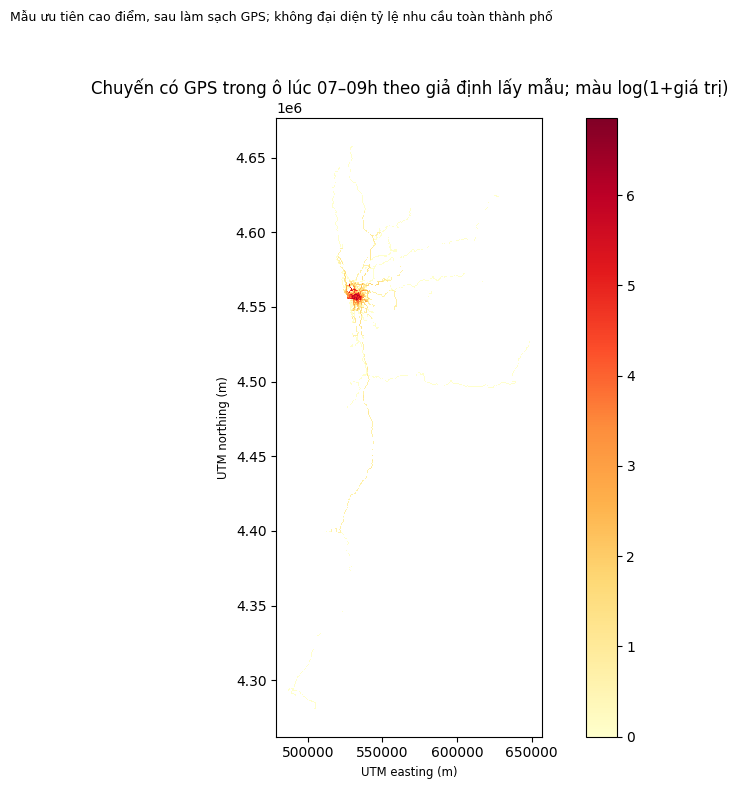

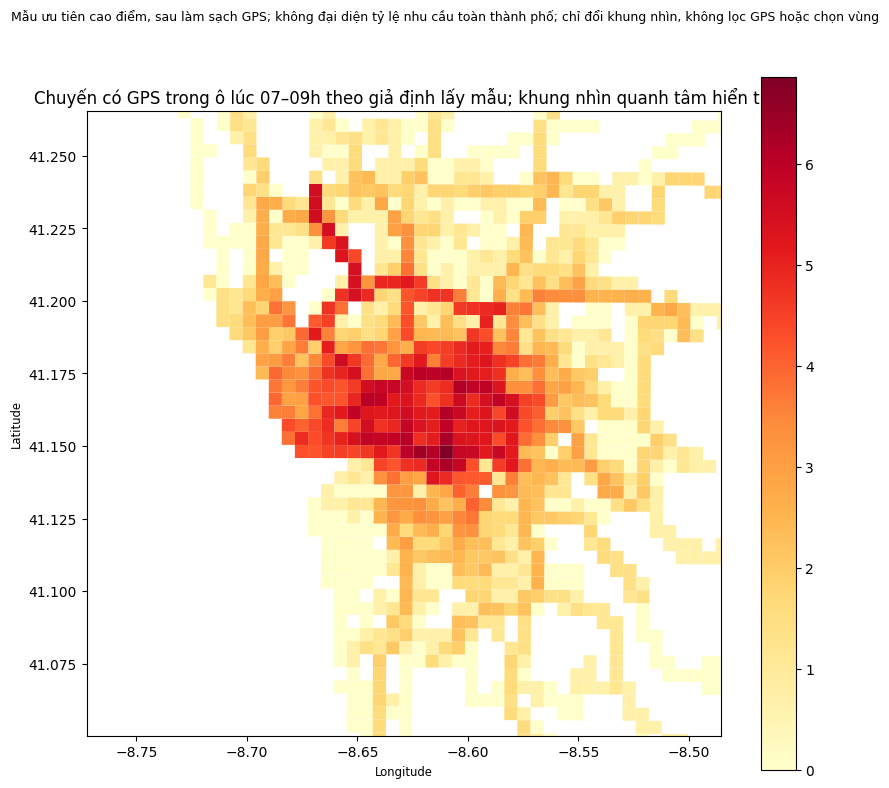

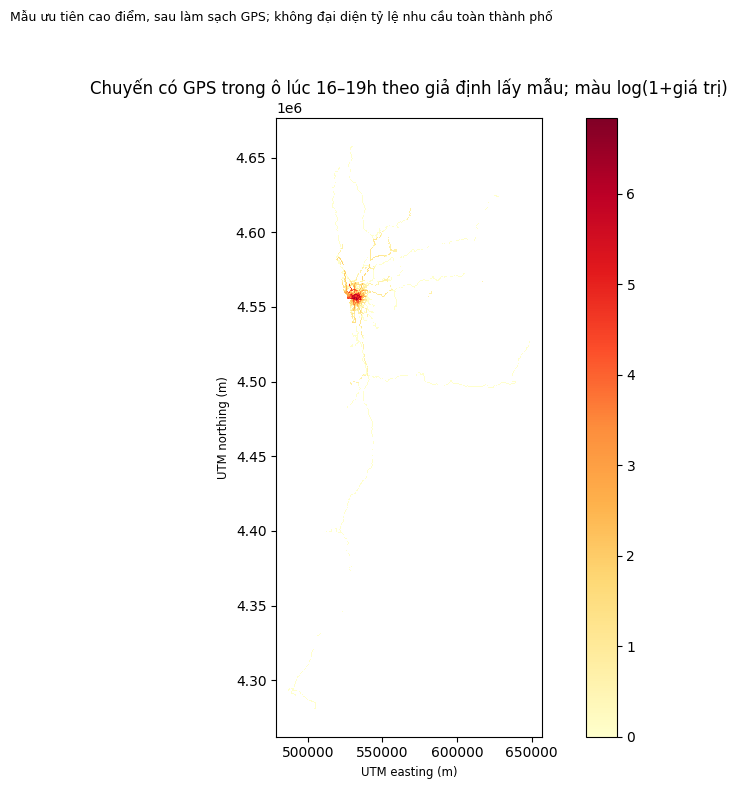

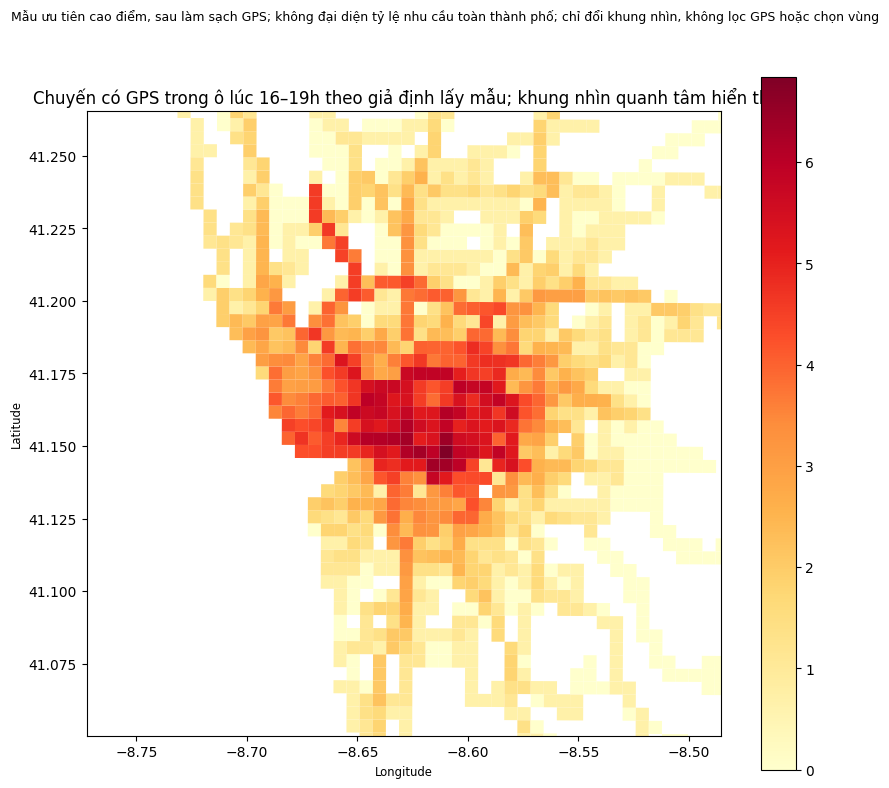

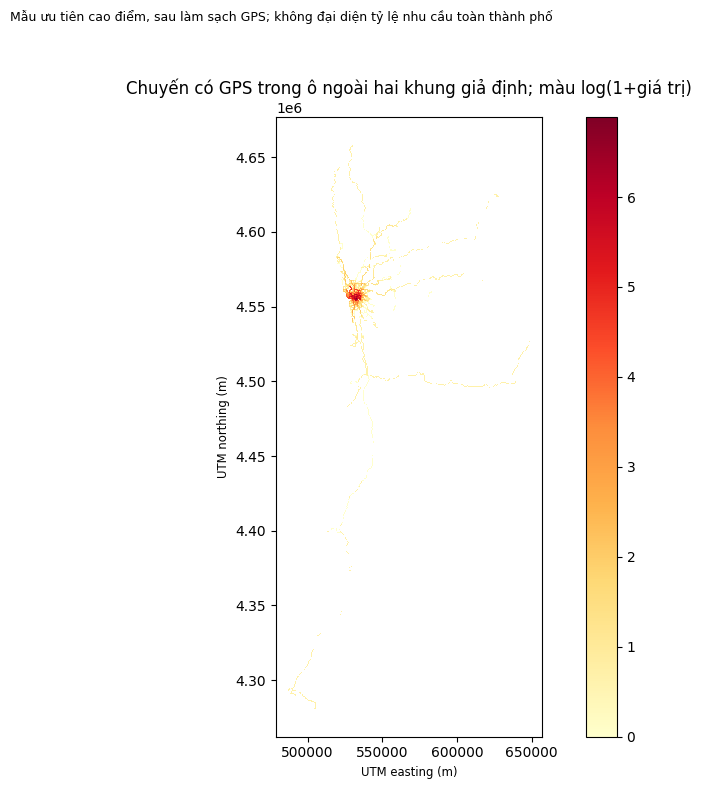

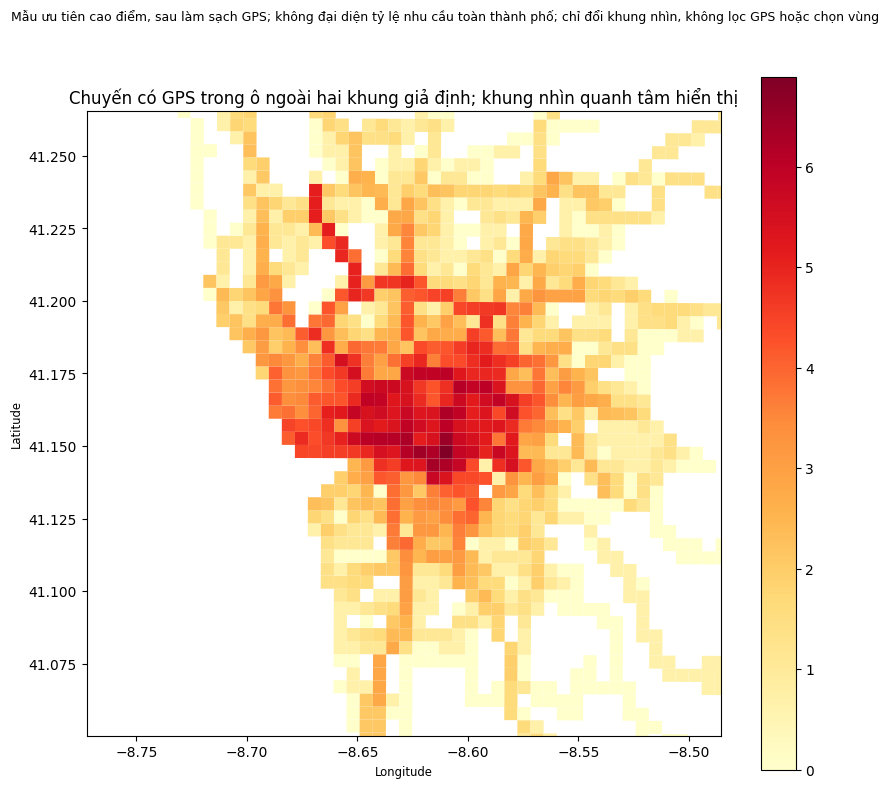

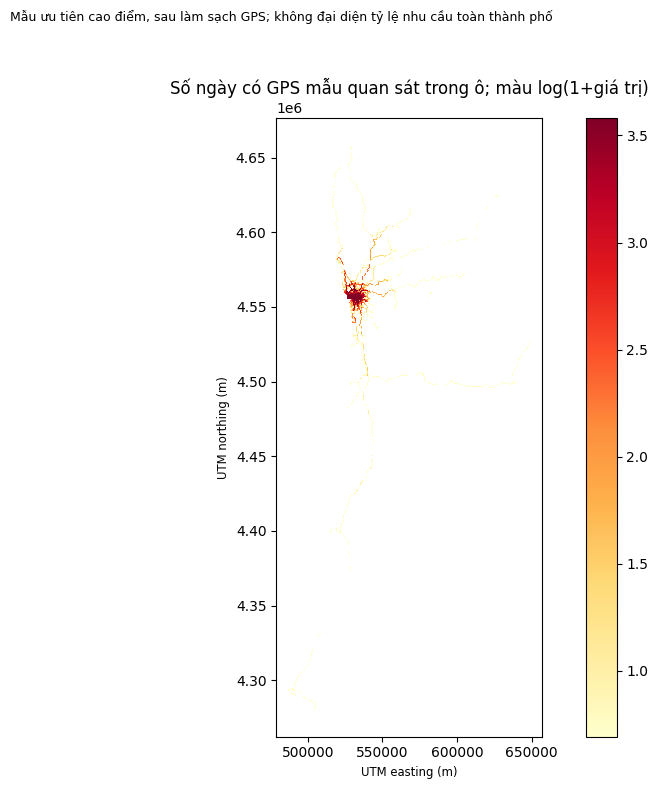

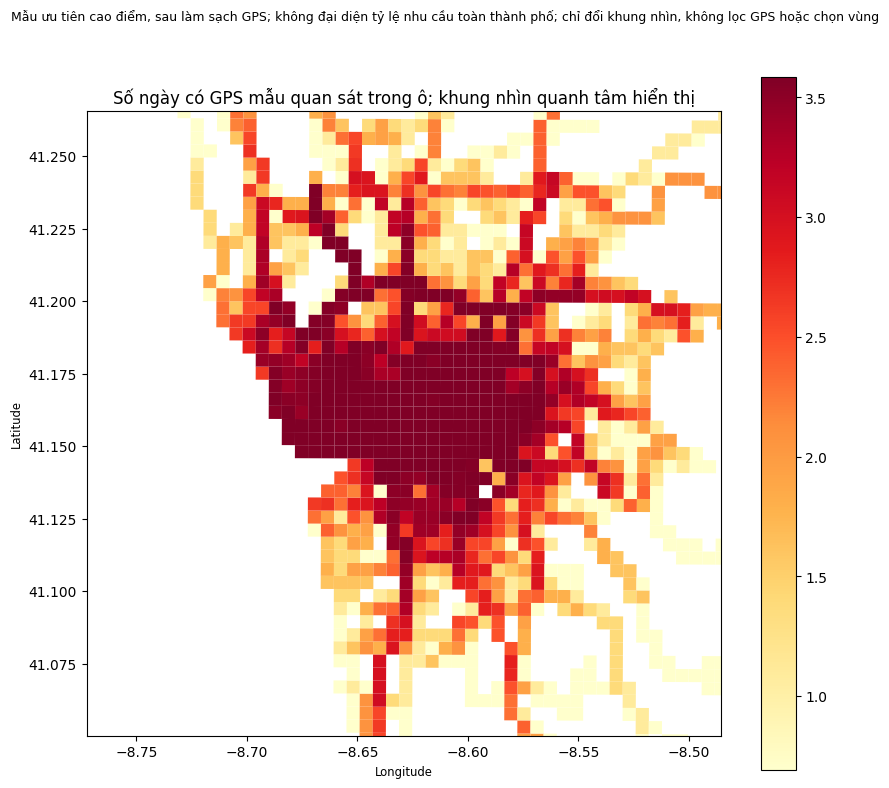

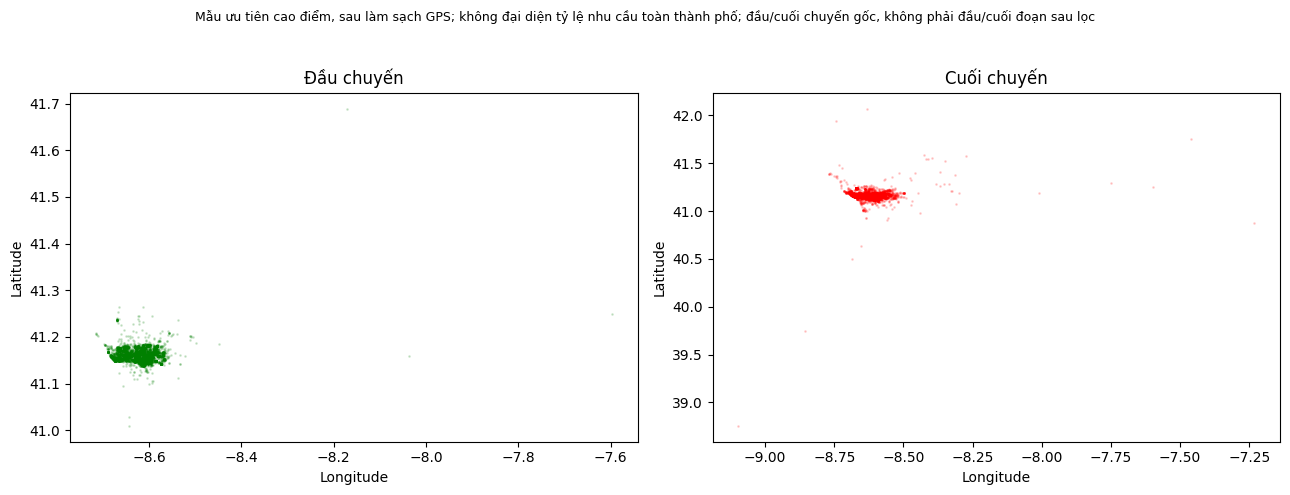

[maps] complete: HTML=True; PNG luôn được xuất, không cần nền bản đồ.
maps_and_static_figures: 10.0s; RSS cuối bước=418.2 MiB (không phải peak)


In [13]:
if GRID_GEO is not None:
    with timed("maps_and_static_figures"):
        for column,name,title in [
            ("n_trips","01_grid_distinct_trips","Số chuyến khác nhau có GPS trong ô"),
            ("morning_peak_n_trips","02_morning_peak",f"Chuyến có GPS trong ô lúc {CFG['peak_windows']['morning_peak'][0]:02d}–{CFG['peak_windows']['morning_peak'][1]:02d}h theo giả định lấy mẫu"),
            ("evening_peak_n_trips","03_evening_peak",f"Chuyến có GPS trong ô lúc {CFG['peak_windows']['evening_peak'][0]:02d}–{CFG['peak_windows']['evening_peak'][1]:02d}h theo giả định lấy mẫu"),
            ("off_peak_n_trips","04_off_peak","Chuyến có GPS trong ô ngoài hai khung giả định"),
            ("n_days","05_observed_days","Số ngày có GPS mẫu quan sát trong ô")]:
            draw_grid_map(GRID_GEO,column,name,title)
        endpoint_maps(POINTS); trajectory_map(POINTS)
        write_json(RUN/"map_render_report.json",MAP_REPORT)
        status("maps","complete" if HAS_FOLIUM else "partial",f"HTML={HAS_FOLIUM}; PNG luôn được xuất, không cần nền bản đồ.")
else: status("maps","blocked","Cần thống kê lưới.")

## H1. Nhập cell_id muốn xem heatmap

Lấy ID từ tooltip hoặc bảng `outputs/csv/region_eda/<run_id>/grid_cells.csv`. Để danh sách rỗng thì chưa vẽ heatmap
theo ô; EDA còn lại vẫn chạy. Khi đổi danh sách, chỉ cần chạy lại H1 và H2.

In [14]:
HEATMAP_CELL_IDS=CFG["heatmap_cell_ids"]
# Ví dụ cú pháp sau khi có ID thật: HEATMAP_CELL_IDS = ["g500_..._..."]

In [15]:
def plot_cell_heatmaps(ids,cell_weekday_time):
    for cell_id in ids:
        part=cell_weekday_time[cell_weekday_time.cell_id==cell_id]
        if part.empty:
            print("Không có GPS mẫu cho cell_id:",cell_id); continue
        matrix=part.pivot(index="weekday",columns="slot",values="n_trips").reindex(index=range(7),columns=range(1440//CFG["time_bin_minutes"]))
        # NaN là không có GPS mẫu; không diễn giải là không có xe.
        fig,ax=plt.subplots(figsize=(12,3.5))
        image=ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),aspect="auto",cmap="YlOrRd")
        ax.set(title=f"{cell_id}: distinct trip theo THỜI GIAN ĐIỂM GPS",xlabel=f"Slot {CFG['time_bin_minutes']} phút",ylabel="Thứ (0=Hai, 6=CN)")
        fig.colorbar(image,ax=ax,label="Chuyến có GPS mẫu")
        figure("cell_heatmap_"+re.sub(r"[^A-Za-z0-9_-]","_",cell_id),SCOPE_SAMPLE+"; ô trống = chưa có GPS trong mẫu")

In [16]:
# H2. Ch?y cell n?y sau khi nh?p cell_id ? H1.
if GRID is not None and HEATMAP_CELL_IDS:
    plot_cell_heatmaps(HEATMAP_CELL_IDS,GRID["cell_weekday_time"])
elif not HEATMAP_CELL_IDS:
    print("Chưa nhập cell_id ở H1; không tự chọn vùng hoặc ô phân tích thay bạn.")

Chưa nhập cell_id ở H1; không tự chọn vùng hoặc ô phân tích thay bạn.


## R1. Nhập một hoặc nhiều bounding box muốn khảo sát

Sửa dòng REGIONS dưới đây thành danh sách của bạn, hoặc sửa CFG['regions'] ở cell A.
Format: `{'name': 'ten_vung', 'bbox': [west, south, east, north]}` theo lon/lat WGS84.
Mặc định rỗng; notebook không tự chọn vùng. Sau khi đổi vùng, chỉ chạy lại **R1 và R2**.
Đổi kích thước ô: sửa cell A, chạy lại cell A, **F → G → R1 → R2**, giữ các hàm đã chạy.
Nếu restart kernel: Run All; metadata/mẫu/GPS được lấy từ cache, không quét CSV lại.

In [17]:
REGIONS=CFG["regions"]
# Ví dụ cú pháp, KHÔNG phải đề xuất vùng: REGIONS = [{"name":"vung_cua_toi", "bbox":[-8.65,41.14,-8.60,41.18]}]
names=[]
for region in REGIONS:
    if not isinstance(region,dict) or set(region)!={"name","bbox"}: raise ValueError("Mỗi vùng cần đúng name và bbox.")
    west,south,east,north=map(float,region["bbox"])
    if not (-180<=west<east<=180 and -80<south<north<84): raise ValueError("Bounding box không hợp lệ.")
    if not str(region["name"]).strip(): raise ValueError("Tên vùng không được rỗng.")
    region["bbox"]=[west,south,east,north]; region["name"]=str(region["name"])
    names.append(str(region["name"]))
if len(names)!=len(set(names)): raise ValueError("Tên vùng phải khác nhau.")
print("Các vùng do người dùng nhập:",REGIONS)

Các vùng do người dùng nhập: []


## R2. Thống kê và so sánh vùng do bạn nhập

Có hai loại bằng chứng được báo riêng: (1) điểm GPS thực nằm trong bbox; (2) dây cung
nối hai GPS liên tiếp cắt qua bbox dù hai đầu ở ngoài. Loại (2) là **nội suy hình học**,
không xác nhận đường xe thật đã chạy. Chỉ xét cặp cùng segment và index gốc liên tiếp.
Distinct trip toàn vùng được tính trên tập ID, tuyệt đối không cộng số chuyến các ô.

Các phần trong vùng giữ UTC timestamp gốc. Chỉ thời điểm cắt biên giữa hai mẫu được
nội suy theo tỷ lệ khoảng cách; mỗi lần ra rồi vào lại tạo visit_id khác. Dừng tại cùng
điểm trong vùng vẫn giữ duration. Biểu đồ giờ/ngày chính dùng thời gian điểm GPS thực.
Độ phủ ô có mẫu số cả các ô cắt vùng nhưng không có GPS; “không quan sát” không phải
“không có taxi”. Gini và top-cell share mô tả độ tập trung quan sát mẫu.

In [18]:
def points_in_bbox(points,bbox):
    west,south,east,north=bbox
    return points.lon.between(west,east)&points.lat.between(south,north)

def make_gps_intervals(points):
    ordered=points.sort_values(["trip_id","segment_id","original_index"]).reset_index(drop=True)
    next_rows=ordered.groupby(["trip_id","segment_id"],sort=False)[["original_index","timestamp","x","y"]].shift(-1)
    valid=next_rows.original_index.eq(ordered.original_index+1)
    intervals=ordered.loc[valid,["trip_id","taxi_id","segment_id","original_index","timestamp","x","y"]].copy().reset_index(drop=True)
    for column in ["original_index","timestamp","x","y"]:
        intervals["next_"+column]=next_rows.loc[valid,column].to_numpy()
    coords=np.stack([intervals[["x","y"]].to_numpy(),intervals[["next_x","next_y"]].to_numpy()],axis=1)
    geometries=shapely.linestrings(coords) if len(intervals) else np.empty(0,dtype=object)
    return intervals,geometries,shapely.STRtree(geometries)

def clip_gps_intervals(intervals,geometries,tree,bbox):
    polygon=shapely.transform(box(*bbox),PROJECT.transform,interleaved=False)
    indices=tree.query(polygon,predicate="intersects")
    rows=[]
    for index in indices:
        row=intervals.iloc[int(index)]; line=geometries[int(index)]
        if line.length<1e-8:
            if not polygon.covers(Point(row.x,row.y)): continue
            pieces=[(0.,1.,Point(row.x,row.y),Point(row.x,row.y))]
        else:
            intersection=line.intersection(polygon)
            pieces=[]
            for piece in shapely.get_parts(intersection):
                if not isinstance(piece,LineString) or piece.length<=1e-8: continue
                start,end=Point(piece.coords[0]),Point(piece.coords[-1])
                a,b=line.project(start)/line.length,line.project(end)/line.length
                if b<a: a,b,start,end=b,a,end,start
                pieces.append((max(0.,a),min(1.,b),start,end))
        for a,b,left,right in pieces:
            dt=row.next_timestamp-row.timestamp
            entry=pd.Timestamp(row.timestamp+a*dt,unit="s",tz="UTC")
            exit_time=pd.Timestamp(row.timestamp+b*dt,unit="s",tz="UTC")
            if exit_time<=entry: continue
            rows.append({"trip_id":row.trip_id,"taxi_id":row.taxi_id,"segment_id":row.segment_id,
                "original_start_index":int(row.original_index),"original_end_index":int(row.next_original_index),
                "gps_start_time":pd.Timestamp(row.timestamp,unit="s",tz="UTC"),"gps_end_time":pd.Timestamp(row.next_timestamp,unit="s",tz="UTC"),
                "entry_time":entry,"exit_time":exit_time,"duration_s":(exit_time.value-entry.value)/1e9,
                "gps_chord_distance_m":line.length*(b-a),"entry_x":left.x,"entry_y":left.y,"exit_x":right.x,"exit_y":right.y,
                "entry_fraction":a,"exit_fraction":b,"boundary_interpolated":a>1e-8 or b<1-1e-8})
    columns=["trip_id","taxi_id","segment_id","original_start_index","original_end_index","gps_start_time","gps_end_time",
             "entry_time","exit_time","duration_s","gps_chord_distance_m","entry_x","entry_y","exit_x","exit_y","entry_fraction","exit_fraction","boundary_interpolated","visit_id"]
    if not rows: return pd.DataFrame(columns=columns)
    frame=pd.DataFrame(rows).sort_values(["trip_id","segment_id","entry_time"]).reset_index(drop=True)
    previous=frame.shift()
    continuous=(frame.trip_id.eq(previous.trip_id)&frame.segment_id.eq(previous.segment_id)
                &frame.entry_time.eq(previous.exit_time)&((frame.entry_x-previous.exit_x)**2+(frame.entry_y-previous.exit_y)**2).lt(1.))
    frame["visit_id"]=frame.trip_id+":visit"+(~continuous).cumsum().astype(str)
    return frame

def region_cell_distribution(inside,bbox):
    polygon=shapely.transform(box(*bbox),PROJECT.transform,interleaved=False)
    if not np.isfinite(polygon.bounds).all(): raise ValueError("Vùng không phù hợp phép chiếu mét cho Porto.")
    size=CFG["grid_size_m"]; minx,miny,maxx,maxy=polygon.bounds
    ix=range(math.floor(minx/size),math.floor(maxx/size)+1)
    iy=range(math.floor(miny/size),math.floor(maxy/size)+1)
    if len(ix)*len(iy)>CFG["max_region_grid_cells"]: raise ValueError("Vùng quá lớn cho grid vùng; thu nhỏ bbox hoặc tăng grid_size_m.")
    rows=[]
    for x in ix:
        for y in iy:
            area=box(x*size,y*size,(x+1)*size,(y+1)*size).intersection(polygon).area
            if area>1e-4: rows.append({"cell_id":f"g{size}_{x}_{y}","gx":x,"gy":y,"area_inside_region_m2":area})
    cells=pd.DataFrame(rows)
    if cells.empty: return cells
    counts=count_observations(inside,["cell_id"])
    cells=cells.merge(counts,on="cell_id",how="left").fillna({"n_trips":0,"n_taxis":0,"n_days":0,"n_points":0})
    return cells

def concentration(values):
    values=np.sort(np.asarray(values,dtype=float)); total=values.sum(); n=len(values)
    if n==0 or total<=0: return {"gini_trip_cell_memberships":np.nan,"top_10pct_membership_share":np.nan}
    gini=2*np.dot(np.arange(1,n+1),values)/(n*total)-(n+1)/n
    return {"gini_trip_cell_memberships":float(gini),"top_10pct_membership_share":float(values[-max(1,math.ceil(n*.1)):].sum()/total)}

def analyse_regions(regions,points,grid_key,grid_geo):
    key=digest([grid_key,regions,{k:CFG[k] for k in ["coverage_min_trips","coverage_min_taxis","coverage_min_days","max_region_grid_cells"]},stage_hash("regions")])[:20]
    folder=RUN/"regions"/key; folder.mkdir(parents=True,exist_ok=True)
    cache=CACHE/"regions"/key; cache.mkdir(parents=True,exist_ok=True)
    marker=cache/"complete.json"
    if marker.exists() and not CFG["force_regions"]:
        saved=json.loads(marker.read_text(encoding="utf-8"))
        for filename in saved["tables"]:
            frame=pd.read_parquet(cache/filename); save_table(frame,folder/filename,csv=not filename.endswith("fragments.parquet"))
        comparison=pd.read_parquet(cache/"comparison.parquet")
    else:
        marker.unlink(missing_ok=True)
        table_names=[]; summaries=[]
        intervals,geometries,tree=make_gps_intervals(points) if regions else (None,None,None)
        for region in regions:
            name=region["name"]; bbox=region["bbox"]; token=digest(region)[:10]
            inside=points[points_in_bbox(points,bbox)].copy()
            fragments=clip_gps_intervals(intervals,geometries,tree,bbox)
            cells=region_cell_distribution(inside,bbox)
            point_ids=set(inside.trip_id); chord_ids=set(fragments.trip_id)
            any_ids=point_ids|chord_ids
            all_taxis=set(inside.taxi_id)|set(fragments.taxi_id)
            summary={"region":name,"bbox_json":json.dumps(bbox),"n_trips_points_inside":len(point_ids),
                "n_trips_chord_intersects":len(chord_ids),"n_trips_any_evidence":len(any_ids),
                "n_trips_chord_only":len(chord_ids-point_ids),"n_taxis_points_inside":inside.taxi_id.nunique(),
                "n_taxis_any_evidence":len(all_taxis),"n_days_points_inside":inside.date.nunique(),"n_gps_points_inside":len(inside),
                "n_region_visits":fragments.visit_id.nunique(),"gps_chord_duration_in_region_s":float(fragments.duration_s.sum()),
                "n_grid_cells_intersecting_region":len(cells),"n_cells_observed":int(cells.n_trips.gt(0).sum()) if len(cells) else 0,
                "fraction_cells_observed":float(cells.n_trips.gt(0).mean()) if len(cells) else 0,
                "n_cells_meeting_config_support":int((cells.n_trips.ge(CFG["coverage_min_trips"])&cells.n_taxis.ge(CFG["coverage_min_taxis"])&cells.n_days.ge(CFG["coverage_min_days"])).sum()) if len(cells) else 0,
                **concentration(cells.n_trips if len(cells) else [])}
            for period in ["morning_peak","evening_peak","off_peak"]:
                p=inside[inside.period==period]
                summary[period+"_n_trips"]=p.trip_id.nunique(); summary[period+"_n_taxis"]=p.taxi_id.nunique(); summary[period+"_n_days"]=p.date.nunique()
            summaries.append(summary)
            tables={token+"_cell_distribution":cells,token+"_daily":count_observations(inside,["date"]),
                    token+"_hourly":count_observations(inside,["hour"]),
                    token+"_weekday_hour":count_observations(inside,["weekday","hour"]),
                    token+"_time":count_observations(inside,["date","day_group","slot","period"]),
                    token+"_fragments":fragments}
            for label,table in tables.items():
                table=table.assign(region=name,scope=SCOPE_SAMPLE+"; vùng do người dùng nhập")
                filename=label+".parquet"; save_table(table,cache/filename,csv=False)
                save_table(table,folder/filename,csv=not label.endswith("fragments")); table_names.append(filename)
        comparison=pd.DataFrame(summaries,columns=None if summaries else ["region","bbox_json","n_trips_points_inside","n_trips_any_evidence","n_gps_points_inside"])
        comparison["scope"]=SCOPE_SAMPLE+"; so sánh vùng, không tự chọn vùng cuối"
        save_table(comparison,cache/"comparison.parquet",csv=False); table_names.append("comparison.parquet")
        write_json(marker,{"tables":table_names,"key":key,"regions":regions})
    save_table(comparison,folder/"comparison.parquet")
    write_json(folder/"regions_entered.json",regions)
    write_json(RUN/"latest_regions.json",{"key":key,"folder":str(folder),"regions":regions})
    for region in regions:
        token=digest(region)[:10]
        daily=pd.read_parquet(folder/(token+"_daily.parquet")); hourly=pd.read_parquet(folder/(token+"_hourly.parquet"))
        fig,axes=plt.subplots(1,2,figsize=(13,4))
        if len(daily): axes[0].bar(pd.to_datetime(daily.date),daily.n_trips)
        if len(hourly):
            axes[1].bar(hourly.hour,hourly.n_trips)
        axes[0].set(title=region["name"]+": chuyến / ngày có GPS trong vùng",ylabel="Distinct trip trong ngày")
        axes[1].set(title="Quan sát theo giờ điểm GPS",xlabel="Giờ Lisbon",ylabel="Distinct trip trong giờ")
        figure("region_"+token+"_temporal",SCOPE_SAMPLE+"; vùng "+region["name"])
    if regions:
        draw_grid_map(grid_geo,"n_trips","08_regions_overlay","Các vùng do người dùng nhập trên lưới GPS mẫu",regions)
    return comparison,folder

In [19]:
if POINT_CELLS is not None:
    with timed("user_regions"):
        REGION_COMPARISON,REGION_FOLDER=analyse_regions(REGIONS,POINT_CELLS,GRID_KEY,GRID_GEO)
        display(REGION_COMPARISON)
        status("regions","complete",f"{len(REGIONS)} vùng do bạn nhập; danh sách rỗng không chặn EDA.")
else: status("regions","blocked","Cần GPS mẫu; các hàm lọc vùng đã được định nghĩa.")

,region,bbox_json,n_trips_points_inside,n_trips_any_evidence,n_gps_points_inside,scope


[regions] complete: 0 vùng do bạn nhập; danh sách rỗng không chặn EDA.
user_regions: 0.1s; RSS cuối bước=419.1 MiB (không phải peak)


## I. Kiểm thử logic (fixture kỹ thuật, không phải số liệu Porto)

Kiểm tra timestamp gốc, không nối qua điểm lỗi, giữ dừng lâu, phân nhóm theo từng GPS,
distinct trip không đếm lặp, midnight/DST, quota và thiếu tầng, CSV/ZIP/schema alias,
chuyến bắt đầu ngoài vùng, dây cung cắt vùng dù không có điểm bên trong, tách lần ra/vào,
bảo toàn timestamp ở biên và cache lấy mẫu không phụ thuộc grid/bounding box.

In [20]:
def run_logic_tests():
    import tempfile
    results=[]
    def check(name,condition):
        if not bool(condition): raise AssertionError(name)
        results.append({"test":name,"status":"passed","scope":"Fixture kỹ thuật tổng hợp, không phải kết quả Porto"})
    original_cfg=CFG.copy(); original_cache=globals()["CACHE"]; original_start=globals()["START"]; original_end=globals()["END"]
    try:
        globals()["START"]=pd.Timestamp("2013-07-01T00:00:00+01:00").tz_convert("UTC")
        globals()["END"]=pd.Timestamp("2013-07-05T00:00:00+01:00").tz_convert("UTC")
        CFG.update(min_trip_points=4,min_segment_points=2,max_gps_speed_kmh=150,broad_geo_bbox=[-10,38,-6,43],
                   peak_windows={"morning_peak":[7,9],"evening_peak":[16,19]},sample_trips=12,peak_fraction=.7,
                   morning_share_of_peak=.5,force_metadata=False,force_sample=False)
        base=int((START+pd.Timedelta(hours=9)).timestamp())
        raw=[[-8.62+i*.00001,41.16] for i in range(10)]; raw[4]=[None,41.16]
        kept,audit=clean_gps(json.dumps(raw),base,"fixture","taxi")
        check("timestamp_uses_original_index",all(p["timestamp"]==base+15*p["original_index"] for p in kept) and any(p["original_index"]==5 for p in kept))
        check("invalid_point_creates_segment_gap",len({p["segment_id"] for p in kept})==2)
        outside=raw.copy(); outside[4]=[-100,41]
        kept,audit=clean_gps(json.dumps(outside),base)
        check("broad_geography_not_small_region_filter",audit["outside_broad_geography"]==1 and audit["kept_points"]==9)
        stationary=[[-8.62,41.16]]*5
        kept,audit=clean_gps(json.dumps(stationary),base)
        check("zero_speed_points_retained",len(kept)==5 and audit["gps_distance_m"]==0 and audit["retained_duration_s"]==60)
        _,audit=clean_gps(json.dumps(stationary),base,missing_flag=True)
        check("missing_data_true_separate",audit["reason"]=="missing_data_true")
        jump=[[-8.62+i*.00001,41.16] for i in range(12)]; jump[5]=[-8.3,41.16]
        kept,audit=clean_gps(json.dumps(jump),base)
        check("gps_jump_splits_without_time_compression",audit["jump_links"]>=1 and all(p["timestamp"]==base+15*p["original_index"] for p in kept))
        begin=int(pd.Timestamp("2013-07-01T08:59:45+01:00").timestamp())
        x,y=PROJECT.transform(-8.62,41.16)
        fixture=pd.DataFrame([{"trip_id":"a","taxi_id":"ta","original_index":i,"timestamp":begin+15*i,
            "lon":-8.62,"lat":41.16,"x":x,"y":y,"segment_id":"a:0","is_original_start":i==0,"is_original_end":i==3} for i in range(4)])
        tagged=attach_grid(fixture,CFG["grid_size_m"])
        check("point_time_not_departure_time",tagged.period.iloc[0]=="morning_peak" and tagged.period.iloc[1]=="off_peak")
        stats=grid_statistics(tagged)
        check("distinct_trip_not_gps_point_count",stats[0].n_trips.iloc[0]==1 and stats[0].n_points.iloc[0]==4)
        check("trip_can_appear_in_multiple_time_buckets",stats[3].n_trips.sum()==2)
        midnight=fixture.iloc[:2].copy(); midnight.timestamp=[int(pd.Timestamp("2013-07-01T23:59:45+01:00").timestamp()),int(pd.Timestamp("2013-07-02T00:00:00+01:00").timestamp())]
        check("midnight_uses_each_point_date",point_time_columns(midnight).date.nunique()==2)
        dst=fixture.iloc[:2].copy(); dst.timestamp=[int(pd.Timestamp("2013-10-27T00:59:45Z").timestamp()),int(pd.Timestamp("2013-10-27T01:00:00Z").timestamp())]
        tagged_dst=point_time_columns(dst)
        check("dst_preserves_utc_time_difference",tagged_dst.timestamp.diff().iloc[1]==15 and tagged_dst.hour.eq(1).all())
        cap=pd.Series({"a":2,"b":100,"c":100}); q=allocate(cap,pd.Series({"a":.7,"b":.15,"c":.15}),20)
        check("quota_redistributes_short_stratum",q.sum()==20 and q.a==2 and (q<=cap).all())
        cap=pd.Series([100]*5); q=allocate(cap,pd.Series([1.]*5),23)
        check("daily_quota_balanced",q.max()-q.min()<=1)
        west,south=UNPROJECT.transform(x-40,y-40); east,north=UNPROJECT.transform(x+40,y+40)
        bbox=[west,south,east,north]
        def make_path(xs,trip="path",indices=None,segments=None):
            indices=list(range(len(xs))) if indices is None else indices
            segments=[trip+":0"]*len(xs) if segments is None else segments
            lon,lat=UNPROJECT.transform(np.asarray(xs)+x,np.full(len(xs),y))
            return pd.DataFrame({"trip_id":trip,"taxi_id":"taxi","original_index":indices,
                "timestamp":[base+15*i for i in indices],"x":np.asarray(xs)+x,"y":y,"lon":lon,"lat":lat,"segment_id":segments})
        path=make_path([-200,0,200,0,-200])
        check("region_trip_can_start_outside",not points_in_bbox(path,bbox).iloc[0] and path.loc[points_in_bbox(path,bbox),"trip_id"].nunique()==1)
        intervals,geoms,tree=make_gps_intervals(path); clipped=clip_gps_intervals(intervals,geoms,tree,bbox)
        check("region_exit_reentry_separate_visits",clipped.visit_id.nunique()==2)
        check("region_original_utc_time_bounds",(clipped.entry_time>=clipped.gps_start_time).all() and (clipped.exit_time<=clipped.gps_end_time).all())
        check("region_boundary_interpolation_explicit",clipped.boundary_interpolated.any() and clipped.duration_s.gt(0).all())
        crossing=make_path([-200,200],"crossing"); intervals,geoms,tree=make_gps_intervals(crossing)
        clipped=clip_gps_intervals(intervals,geoms,tree,bbox)
        check("chord_only_crossing_reported",not points_in_bbox(crossing,bbox).any() and clipped.trip_id.nunique()==1)
        gap=make_path([-200,200],"gap",[0,5],["gap:0","gap:1"])
        intervals,geoms,tree=make_gps_intervals(gap)
        check("no_region_connection_across_gap",len(intervals)==0)
        stay=make_path([0,0],"stay"); intervals,geoms,tree=make_gps_intervals(stay)
        clipped=clip_gps_intervals(intervals,geoms,tree,bbox)
        check("stationary_region_duration_retained",abs(clipped.duration_s.sum()-15)<1e-6)
        same_trip=pd.DataFrame({"trip_id":["a","a"],"taxi_id":["t","t"],"date":["2013-07-01"]*2,"cell_id":["cell1","cell2"]})
        check("region_distinct_not_sum_of_cells",same_trip.trip_id.nunique()==1 and count_observations(same_trip,["cell_id"]).n_trips.sum()==2)
        with tempfile.TemporaryDirectory(prefix="porto_region_logic_") as temp:
            globals()["CACHE"]=Path(temp)/"cache"; CACHE.mkdir()
            rows=[]
            for day in range(3):
                for j,hour in enumerate([7,8,16,17,12,22]):
                    rows.append({"TRIP_ID":f"fixture_{day}_{j}","TAXI_ID":f"taxi{j%3}","TIMESTAMP":int((START+pd.Timedelta(days=day,hours=hour)).timestamp()),
                        "CALL_TYPE":"A","ORIGIN_CALL":None,"ORIGIN_STAND":None,"DAY_TYPE":"A","MISSING_DATA":False,"POLYLINE":json.dumps(stationary)})
            rows.append(rows[0].copy()); rows.append({**rows[0],"TRIP_ID":"missing","MISSING_DATA":True})
            rows.append({**rows[0],"TRIP_ID":"bad_time","TIMESTAMP":"invalid"})
            csv=Path(temp)/"train.csv"; pd.DataFrame(rows).to_csv(csv,index=False)
            archive=Path(temp)/"train.zip"
            with zipfile.ZipFile(archive,"w") as z: z.write(csv,"nested/train.csv")
            with input_stream(archive) as stream: check("zip_csv_reader",len(pd.read_csv(stream))==len(rows))
            columns,aliases=schema_for(csv); check("day_type_alias_no_daytype_inference",aliases.get("DAY_TYPE")=="DAYTYPE")
            db,report,key=metadata_database(csv,{"sha256":"fixture_only"})
            check("metadata_duplicate_and_missing_counts",report["counts"]["duplicate_trip_id_rows"]==1 and report["counts"]["missing_data_true_rows"]==1 and report["counts"]["invalid_timestamp_rows"]==1)
            sample,strata,groups,key1=make_selection(db,key)
            check("seeded_stratified_sample_budget",len(sample)==12 and sample.trip_id.is_unique and sample.day.nunique()==3)
            CFG["grid_size_m"]=1000; CFG["regions"]=[{"name":"fixture_region","bbox":bbox}]
            cached,_,_,key2=make_selection(db,key)
            check("grid_region_changes_do_not_invalidate_sampling",key1==key2 and cached.trip_id.tolist()==sample.trip_id.tolist())
    finally:
        CFG.clear(); CFG.update(original_cfg)
        globals()["CACHE"]=original_cache; globals()["START"]=original_start; globals()["END"]=original_end
    return pd.DataFrame(results)

In [21]:
if CFG["run_logic_tests"]:
    with timed("logic_tests_fixture_only"):
        LOGIC_TESTS=run_logic_tests(); save_table(LOGIC_TESTS,RUN/"logic_tests.parquet")
        display(LOGIC_TESTS); status("logic_tests","complete",f"{len(LOGIC_TESTS)} passed; chỉ kiểm thử fixture.")

,test,status,scope
0,timestamp_uses_original_index,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
1,invalid_point_creates_segment_gap,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
2,broad_geography_not_small_region_filter,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
3,zero_speed_points_retained,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
4,missing_data_true_separate,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
5,gps_jump_splits_without_time_compression,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
6,point_time_not_departure_time,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
7,distinct_trip_not_gps_point_count,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
8,trip_can_appear_in_multiple_time_buckets,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."
9,midnight_uses_each_point_date,passed,"Fixture kỹ thuật tổng hợp, không phải kết quả ..."


[logic_tests] complete: 26 passed; chỉ kiểm thử fixture.
logic_tests_fixture_only: 0.3s; RSS cuối bước=421.1 MiB (không phải peak)


## J. Đọc kết quả và chạy lại

- Sửa `CFG['data_path']` ở cell A; dùng CSV hoặc ZIP có train.csv. Lần đầu Run All.
- Xem metadata_all/study để phân biệt phân bố toàn file và trong khoảng khảo sát.
- Xem bản đồ 01 rồi 02/03/04/05; màu thể hiện quan sát mẫu, không phải tốc độ/ùn tắc.
- Chọn cell_id từ tooltip và chạy H1/H2 nếu muốn heatmap theo ô.
- Nhập vùng ở R1 rồi chạy R2; so sánh distinct trip/taxi/ngày, dữ liệu từng nhóm giờ,
  phân bố giữa các ô, và mức thiếu ngày. Bạn tự quyết định vùng cuối cùng.
- Đổi bbox: R1/R2. Đổi grid: cell A, F/G, R1/R2 (giữ helpers trong kernel), hoặc
  Run All để tận dụng cache. Metadata/mẫu/GPS không phụ thuộc grid hay regions.
- Đổi seed/tỷ lệ/ngày sẽ chọn lại mẫu từ SQLite; cần đọc POLYLINE mẫu mới.
- Hash file được memo theo path/size/mtime; cùng file không đọc lại toàn CSV chỉ để hash.
  Nếu nghi thay đổi file nhưng giữ nguyên thông tin này, bật verify_full_hash.

Mỗi lần Run All xuất thư mục riêng. `outputs/region_eda/latest_run.json` trỏ tới kết quả
mới nhất. Thư mục regions có cache/key riêng và `latest_regions.json` ghi bbox thật đã nhập.
Không có đường/cạnh OSM, model, nhãn ùn tắc hoặc suy luận số cạnh từ ô lưới trong kết quả.

In [22]:
write_json(RUN/"cache_keys.json",{"metadata":META_KEY,"sample":SAMPLE_KEY,"clean":CLEAN_KEY,"grid":GRID_KEY})
write_json(RUN/"manifest.json",{"config":CFG,"seed":CFG["seed"],"packages":VERSIONS,"statuses":STATUS,
    "scopes":{"metadata_all":SCOPE_META_ALL,"metadata_study":SCOPE_META_STUDY,"gps_grid_regions":SCOPE_SAMPLE},
    "regions_entered":REGIONS,"runtime":RUNTIME,"created_utc":datetime.now(timezone.utc).isoformat(),
    "artifacts":sorted(str(p.relative_to(RUN)) for p in RUN.rglob("*") if p.is_file())})
write_json(OUTPUT/"latest_run.json",{"folder":str(RUN),"statuses":STATUS,"regions":REGIONS})
display(pd.DataFrame(STATUS).T)
print("Kết quả EDA:",RUN)
print("Bản đồ HTML:",MAPS)
print("Chưa có vùng cuối cùng: người dùng tự xem và quyết định; không suy ra số cạnh đường.")

,status,message
metadata,complete,"1,710,670 dòng; metadata lưu trên SQLite."
sampling,complete,"10,000 chuyến, 35 ngày; seed=313."
gps,complete,"9,793 chuyến; 487,590 GPS mẫu giữ lại."
grid,complete,"3,516 ô có GPS mẫu; ô không phải cạnh đường."
maps,complete,"HTML=True; PNG luôn được xuất, không cần nền b..."
regions,complete,0 vùng do bạn nhập; danh sách rỗng không chặn ...
logic_tests,complete,26 passed; chỉ kiểm thử fixture.


Kết quả EDA: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_eda\20261021T155220459810Z
Bản đồ HTML: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_eda\20261021T155220459810Z\maps
Chưa có vùng cuối cùng: người dùng tự xem và quyết định; không suy ra số cạnh đường.


## Tài liệu tham khảo

- [Kaggle — ECML/PKDD 15 Taxi Trajectory Prediction I, train.csv](https://www.kaggle.com/competitions/pkdd-15-predict-taxi-service-trajectory-i/data).
- `porto_trajectory_mining.ipynb` trong workspace: chỉ đọc đường dẫn, seed/khoảng ngày;
  không chạy lại pipeline matching, không sửa file này.
- [pandas read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html),
  [groupby](https://pandas.pydata.org/docs/reference/groupby.html),
  [time series/time zones](https://pandas.pydata.org/docs/user_guide/timeseries.html).
- [NumPy](https://numpy.org/doc/stable/), [PyArrow Parquet](https://arrow.apache.org/docs/python/parquet.html).
- [pyproj Transformer](https://pyproj4.github.io/pyproj/stable/api/transformer.html),
  [Geod](https://pyproj4.github.io/pyproj/stable/api/geod.html): phép chiếu mét và GPS chord distance.
- [Shapely intersects](https://shapely.readthedocs.io/en/stable/reference/shapely.intersects.html),
  [STRtree](https://shapely.readthedocs.io/en/stable/strtree.html),
  [GeoPandas](https://geopandas.org/en/stable/docs.html): lưới, clip bbox và xuất GeoParquet.
- [Folium GeoJSON](https://python-visualization.github.io/folium/latest/user_guide/geojson/geojson.html),
  [Folium marker clusters](https://python-visualization.github.io/folium/latest/user_guide/plugins/marker_cluster.html),
  [Branca](https://python-visualization.github.io/branca/): HTML quan sát mẫu, tooltip và màu.
- [Matplotlib](https://matplotlib.org/stable/), [psutil](https://psutil.readthedocs.io/),
  [IPython display](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html).
- [Python sqlite3](https://docs.python.org/3/library/sqlite3.html),
  [zipfile](https://docs.python.org/3/library/zipfile.html), [hashlib](https://docs.python.org/3/library/hashlib.html),
  [nbformat](https://nbformat.readthedocs.io/), [nbclient](https://nbclient.readthedocs.io/).

OpenStreetMap chỉ là tiles nền tùy chọn của HTML qua Folium (© OpenStreetMap contributors).
Không tải hoặc phân tích road graph; số cạnh đường chưa được xác định ở notebook này.